# Paper figures — multi-seed AROMA vs SAC / rule-based / DP

Figures for the manuscript: sequential v3 AROMA (`seq_v3_catalog`, total-operating-cost adoption) on seeds 1, 41, 61 and 81,
proposer backbones Claude (sonnet-4-6 + haiku-4-5) and GPT (gpt-5.2 + gpt-5-mini). The per-cycle rows come from the stored
evaluation tables in `FCHEV-EMS/evaluation_runs/` (`EVAL_SOURCES`, one row per actor and cycle, with the trace path), the
consolidated table of these runs is `20261020_seq_v3_claude_vs_gpt_seed1_41_61_81_ep399_four_cycles/report.md`.

Protocol
- Evaluation cycles: UDDS, WVUSUB, LA92, HWFET. One deterministic rollout per actor, SOC0 = 0.6, ep399 actors.
- **SAC** = baseline reward (iter1 of each AROMA run, same seed). **AROMA** = the iteration in `PICKS`, one entry per proposer
  backbone: the champion the training-cycle gate finally adopted (last `replace_champion`). When the gate adopted nothing the pick
  is iteration 1, i.e. AROMA equals SAC on that seed (Claude seed 61, GPT seed 81). Both backbones start from the same baseline
  run, so SAC is shared (checked below).
- **DP** (`dp_main_interp_2d.py`, ramp 10 kW/s, w_soc = 500, re-optimised on the current plant) and **rule-based** is the efficient-band power follower after Liu et al. (2020, Energy 118212)
  (`rule_based_eval.py --rb_policy efficient_band --rb_p_off_kw 0.95 --rb_min_off_s 90 --ramp_limit_kw 10`): FC off when the
  demand is below 0.95 kW (the plant's FC-off level), otherwise it follows the demand up to the upper end of its high-efficiency
  band (48.4 kW) and holds there; once off it stays off at least 90 s unless the battery cannot carry the demand or SOC drops
  0.08 below SOC0; SOC balanced on each cycle. Both do not
  depend on the seed; both from `20261021_rb_efficient_band_minoff90/metrics_rb_dp.csv` (DP rows copied from
  `20261013_motor_efficiency_ramp10`; current plant: motor efficiency map, driveline losses, FC start-stop wear per start).
- Fuel is the SOC-corrected equivalent H$_2$ in g/km; CS is the final |ΔSOC| (charge sustaining when ≤ `CS_TOL` = 0.05, the v3
  gate guard); degradation is 1 − SOH at the end of the cycle.
- "4-cycle mean" is the unweighted mean of the four cycles (equal distance on each cycle). Seed statistics are over the per-seed
  4-cycle means. (The `report.md` table weights by distance, so its numbers differ slightly.)

Figures
1. Per-cycle performance, seed mean ± std with the individual seeds as dots.
2. Paired seed comparison SAC → AROMA, and the head-to-head table between the proposer backbones.
3. Representative seed: operating points on the FC efficiency curve, per method and cycle (overview grid).
- S1–S4. Representative seed: FC operating points on the efficiency curve, one 2 × 2 figure per cycle
  (DP, rule-based, baseline SAC, AROMA-SAC of the `SUPP_LLM` backbone).
- 4–6. Economic translation of fuel and FC wear: operating cost per 100 km (hydrogen cost; degradation cost: FC and battery wear), FC stack life
  in km / hours / years, and cumulative cost over the vehicle life, plus a per-year table.
7. Every AROMA iteration on the evaluation cycles, per seed and backbone, with the adopted champion marked.

Backbones: every key of `PICKS` with at least one seed is drawn as its own `AROMA (<backbone>)` method in every figure and
table. Leave a backbone's dict empty to drop it. `REP_LLMS` selects the backbones shown in the overview grid (Figure 3); `SUPP_LLM` is the single backbone shown as AROMA-SAC in Figures S1–S4.

In [1]:
from pathlib import Path
import json
import re
import numpy as np
import pandas as pd
import scipy.io as scio
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

In [2]:
# --- Configuration ---
REPO = Path.cwd().resolve().parent  # run from visualization/
FCHEV_ROOT = REPO / 'FCHEV-EMS'
EVAL_ROOT = REPO / 'results' / 'evaluation_runs'

CYCLES = ['UDDS', 'WVUSUB', 'LA92', 'HWFET']
CYCLE_CLASS = {'UDDS': 'urban driving', 'WVUSUB': 'urban driving', 'LA92': 'aggressive', 'HWFET': 'highway'}

# Stored per-cycle evaluation tables of the seq_v3_catalog runs (aroma_baseline_matched/): (eval dir, files, backbone or None).
# backbone None = the table has an `agent` column (claude / gpt / baseline = the shared iter1 actor).
EVAL_SOURCES = [
    ('20261017_seq_v3_catalog_seed41_61_81_iter1to6_ep399_four_cycles', ['results_with_fc_events.json'], 'GPT'),     # runs seed*_obscur_20261016_*
    ('20261018_seq_v3_catalog_claude_seed41_61_81_iter1to6_ep399_four_cycles', ['metrics.csv'], 'Claude'),          # runs seed*_obscur_20261017_*
    ('20261019_seq_v3_catalog_claude_vs_gpt_seed1_21_iter1to5_ep399_four_cycles', ['metrics.csv', 'metrics_iter6.csv'], None),  # seed1 Claude 113049 / GPT 061824
]
SEED_SET = [1, 41, 61, 81]

# AROMA iteration per seed = champion adopted by the training-cycle gate (run_summary.json); 1 = nothing adopted (AROMA == SAC).
PICKS = {
    'Claude': {1: 2, 41: 5, 61: 1, 81: 2},
    'GPT': {1: 3, 41: 5, 61: 6, 81: 1},
}

# Representative simulation shown in the FC efficiency-map figures: one seed, and the proposers drawn for it.
# Seed 41: the only seed where both backbones adopted a non-baseline reward (both iteration 5).
REP_SEED = 41
REP_LLMS = ['Claude', 'GPT']  # rows of the overview grid (Figure 3)
SUPP_LLM = 'Claude'           # the AROMA-SAC policy of Figures S1-S4

# Seed-independent references on the current plant (motor efficiency map, driveline losses, FC start-stop wear per start):
# DP re-optimised with dp_main_interp_2d.py (w_soc 500, ramp 10 kW/s) and the efficient-band rule (p_off 0.95 kW, min_off 90 s)
# with the same ramp limit; DP rows copied from 20261013_motor_efficiency_ramp10.
REF_TABLE = EVAL_ROOT / '20261021_rb_efficient_band_minoff90' / 'metrics_rb_dp.csv'  # columns method / cycle / ... / trace_path

SOC0 = 0.6
CS_TOL = 0.05  # charge sustaining: |SOC_final - SOC0| <= CS_TOL (v3 gate guard)
SAVE_FIGS = True

# --- Economic translation (Figures 4-6) ---
# End of life: FC 10% voltage loss (the allowed degradation of the plant's FC model, FCHEV_SOH.run_FC_SOH, and of the DOE
# durability target), battery 20% capacity loss. The wear measured on the cycles is extrapolated linearly to these limits.
FC_EOL_LOSS = 0.10
FC_NET_KW = 80.0          # kW_net, FC system net output (DOE reference system; plant P_fc_sys max 79.4 kW, stack 95 kW)
FC_COST_PER_KW = 76.0     # USD/kW_net: DOE Hydrogen Program Record 21001 (80 kW_net system, 100,000 units/yr, 8,000 h)
BATT_EOL_LOSS = 0.20
BATT_KWH = 1.56           # pack energy of the plant (Battery.py: 6.5 Ah at 240 V)
BATT_COST_PER_KWH = 486.0  # USD/kWh: power-type HEV pack, MY2023 (Argonne ANL/CSE-24/1, BatPaC); linear in pack energy between 1.2 kWh (570) and 1.8 kWh (430)
H2_PRICE = 7.0            # USD/kg (1 gge ~ 1 kg), untaxed, dispensed: DOE light-duty 2025 cost target, Program Record 18004 (2016$; ultimate 4). California retail in 2025 is about 30-36 USD/kg.
ANNUAL_KM = 15000.0       # distance driven per year, converts distance to years
DOE_FC_LIFE_H = 8000.0    # DOE durability target for light-duty FC systems
HORIZON_KM = 240000.0     # cumulative-cost figure: 150,000 miles, the vehicle life behind the DOE durability target

In [3]:
# --- Plot style and export (same conventions as eval_viz_*.ipynb) ---
_font = Path('/mnt/c/Windows/Fonts/times.ttf')
if _font.exists():
    font_manager.fontManager.addfont(str(_font))
    plt.rcParams['font.family'] = 'Times New Roman'
else:
    plt.rcParams['font.family'] = 'serif'
plt.rcParams.update({
    'font.size': 12, 'axes.titlesize': 13, 'axes.labelsize': 12, 'xtick.labelsize': 11, 'ytick.labelsize': 11,
    'legend.fontsize': 11, 'figure.dpi': 400, 'mathtext.fontset': 'stix',
    'axes.grid': True, 'grid.alpha': 0.3, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'savefig.bbox': 'tight', 'savefig.facecolor': 'white',
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
})

# Bold, enlarged text for the paper figures (performance, paired-seed, cost split, S1-S4).
for _f in ('timesbd.ttf', 'timesbi.ttf', 'timesi.ttf'):
    _fp = Path('/mnt/c/Windows/Fonts') / _f
    if _fp.exists():
        font_manager.fontManager.addfont(str(_fp))
BOLD_RC = {'font.size': 18, 'axes.titlesize': 20, 'axes.labelsize': 20, 'xtick.labelsize': 18, 'ytick.labelsize': 18,
           'legend.fontsize': 18, 'figure.titlesize': 20, 'figure.titleweight': 'bold', 'font.weight': 'bold', 'axes.labelweight': 'bold', 'axes.titleweight': 'bold',
           'mathtext.fontset': 'custom', 'mathtext.rm': 'Times New Roman:bold',
           'mathtext.it': 'Times New Roman:italic:bold', 'mathtext.bf': 'Times New Roman:bold'}

from matplotlib.ticker import MultipleLocator  # pins the original tick spacing under the larger fonts

FIG_PREFIX = 'multi_seed_v3cat'  # earlier figure set (multi_seed__*) is kept
FIG_OUTDIR = Path('paper_figures')
FIG_FORMATS = ('pdf', 'svg', 'png')
RASTER_DPI = 1000


def save_fig(name, fig=None):
    # Vector (pdf/svg) plus a PNG fallback under paper_figures/<ext>/.
    if not SAVE_FIGS:
        return
    fig = fig if fig is not None else plt.gcf()
    slug = re.sub(r'[^0-9A-Za-z_.-]+', '_', str(name)).strip('_')
    for ext in FIG_FORMATS:
        sub = FIG_OUTDIR / ext
        sub.mkdir(parents=True, exist_ok=True)
        kw = dict(bbox_inches='tight', facecolor='white')
        if ext == 'png':
            kw['dpi'] = RASTER_DPI
        fig.savefig(sub / f'{FIG_PREFIX}__{slug}.{ext}', **kw)
    print(f'[fig] {FIG_PREFIX}__{slug} -> {FIG_OUTDIR}/')

In [4]:
# --- Methods, colours, markers ---
# Colour follows the method in every figure. The first four pass the colour-vision-deficiency check on all pairs;
# the second AROMA proposer additionally carries a hatch and its own marker.
LLMS = [k for k, v in PICKS.items() if v]
REP_LLMS = [l for l in REP_LLMS if l in LLMS and REP_SEED in PICKS[l]]
assert REP_LLMS, f'no proposer in REP_LLMS has seed {REP_SEED}'
assert REP_SEED in PICKS.get(SUPP_LLM, {}), f'{SUPP_LLM} has no pick for seed {REP_SEED}'
AROMA_LABEL = {llm: ('AROMA' if len(LLMS) == 1 else f'AROMA ({llm})') for llm in LLMS}
METHODS = ['DP', 'Rule-based', 'SAC'] + [AROMA_LABEL[l] for l in LLMS]
SEEDED = METHODS[2:]

_aroma_style = [dict(color='#1baf7a', hatch=None, marker='o'), dict(color='#eda100', hatch='///', marker='^')]
STYLE = {'DP': dict(color='#4a3aa7', hatch=None, marker='D'),
         'Rule-based': dict(color='#2a78d6', hatch=None, marker='s'),
         'SAC': dict(color='#eb6834', hatch=None, marker='o')}
STYLE.update({AROMA_LABEL[l]: _aroma_style[i] for i, l in enumerate(LLMS)})
INK = '#222222'
NONCS_COLOR = '#d0312d'  # seed / point that is not charge sustaining
SEEDS = sorted({s for l in LLMS for s in PICKS[l]})
SEED_MARKER = dict(zip(SEEDS, ['o', 's', '^', 'D', 'v', 'P', 'X', '*']))

# column, axis label, scale, log axis
METRICS = [
    ('eq', 'Equivalent H$_2$ consumption (g/km)', 1.0, False),
    ('adsoc', 'Final |$\\Delta$SOC|', 1.0, False),
    ('fc', 'FC SOH loss ($\\times10^{-4}$)', 1e4, True),
    ('bt', 'Battery SOH loss ($\\times10^{-4}$)', 1e4, False),
]

## Data

One row per (method, seed, cycle). `RL` holds every stored actor (all iterations, both backbones); the AROMA rows are the
iterations in `PICKS`. SAC is iter1; the cell checks that both backbones' iter1 rows agree (they are the same actor).

In [5]:
def _load_source(run_dir, files, backbone):
    frames = []
    for f in files:
        p = EVAL_ROOT / run_dir / f
        frames.append(pd.DataFrame(json.loads(p.read_text())) if p.suffix == '.json' else pd.read_csv(p))
    t = pd.concat(frames, ignore_index=True)
    if backbone is not None:
        t['agent'] = backbone
        return t
    t['agent'] = t.agent.map({'claude': 'Claude', 'gpt': 'GPT', 'baseline': 'baseline'})
    base = t[t.agent == 'baseline']  # shared iter1 actor, evaluated once: give it to both backbones
    return pd.concat([t[t.agent != 'baseline'], base.assign(agent='Claude'), base.assign(agent='GPT')], ignore_index=True)


RL = pd.concat([_load_source(*s) for s in EVAL_SOURCES], ignore_index=True)
RL = RL[RL.seed.isin(SEED_SET) & RL.cycle.isin(CYCLES)].copy()
RL['iteration'] = RL.iteration.astype(int)
assert not RL.duplicated(['agent', 'seed', 'iteration', 'cycle']).any()


def _rows(g, method, seed):
    assert len(g) == len(CYCLES), (method, seed, len(g))
    g = g.set_index('cycle').loc[CYCLES].reset_index()
    return pd.DataFrame({
        'method': method, 'seed': seed, 'cycle': g.cycle.values,
        'eq': g.equivalent_h2_g_per_km.values, 'raw': g.raw_h2_g_per_km.values,
        'dsoc': g.final_soc.values - SOC0, 'adsoc': np.abs(g.final_soc.values - SOC0),
        'fc': g.fc_soh_loss.values, 'bt': g.battery_soh_loss.values, 'trace': g.trace_path.values})


def rl_rows(llm, seed, it):
    return RL[(RL.agent == llm) & (RL.seed == seed) & (RL.iteration == it)]


ref = pd.read_csv(REF_TABLE)
VALS = ['eq', 'raw', 'adsoc', 'fc', 'bt']


def build_methods(picks):
    # one row per (method, seed, cycle) for the AROMA iterations in `picks` ({backbone: {seed: iteration}})
    parts, sac_seen = [], {}
    for llm in LLMS:
        for seed, it in picks[llm].items():
            parts.append(_rows(rl_rows(llm, seed, it), AROMA_LABEL[llm], seed))
            sac = _rows(rl_rows(llm, seed, 1), 'SAC', seed)
            if seed not in sac_seen:
                parts.append(sac)
                sac_seen[seed] = sac
            elif not np.allclose(sac[['eq', 'fc', 'bt']], sac_seen[seed][['eq', 'fc', 'bt']], rtol=1e-6):
                print(f'[warn] seed {seed}: the {llm} run has a different iter1 baseline; SAC is taken from the first proposer')
    parts.append(_rows(ref[ref.method == 'DP'], 'DP', np.nan))
    parts.append(_rows(ref[ref.method == 'Rule-based'], 'Rule-based', np.nan))
    m = pd.concat(parts, ignore_index=True)
    m['cycle'] = pd.Categorical(m['cycle'], CYCLES, ordered=True)
    return m


def per_seed(m):
    # per-seed 4-cycle mean (DP / rule-based have a single "seed")
    ps = m.assign(seed=m.seed.fillna(-1)).groupby(['method', 'seed'], observed=True)[VALS].mean().reset_index()
    ps['cs_ok'] = m.assign(seed=m.seed.fillna(-1), ok=m.adsoc <= CS_TOL).groupby(['method', 'seed'], observed=True).ok.sum().values
    return ps


def summarize(ps):
    s = ps.groupby('method')[VALS + ['cs_ok']].mean().loc[METHODS]
    for k in ['eq', 'raw', 'fc', 'bt']:
        s[f'{k}_vs_SAC_%'] = (s[k] / s.loc['SAC', k] - 1) * 100
    s['eq_vs_DP_%'] = (s['eq'] / s.loc['DP', 'eq'] - 1) * 100
    return s


M = build_methods(PICKS)
PS = per_seed(M)
summary = summarize(PS)
pd.set_option('display.width', 220)
print(f'seeds: {SEEDS}; AROMA picks: {PICKS}')
print('not charge sustaining (|dSOC| > CS_TOL):', ', '.join(f'{r.method} s{int(r.seed)} {r.cycle} {r.dsoc:+.3f}'
                                                          for r in M[M.adsoc > CS_TOL].itertuples()) or 'none')
summary.T

seeds: [1, 41, 61, 81]; AROMA picks: {'Claude': {1: 2, 41: 5, 61: 1, 81: 2}, 'GPT': {1: 3, 41: 5, 61: 6, 81: 1}}
not charge sustaining (|dSOC| > CS_TOL): SAC s1 LA92 +0.061, SAC s1 HWFET +0.056, SAC s41 UDDS +0.098, SAC s41 WVUSUB +0.069, SAC s41 LA92 +0.053, SAC s81 UDDS +0.090, SAC s81 WVUSUB +0.082, SAC s81 LA92 +0.070, AROMA (GPT) s1 HWFET +0.062, AROMA (GPT) s81 UDDS +0.090, AROMA (GPT) s81 WVUSUB +0.082, AROMA (GPT) s81 LA92 +0.070


method,DP,Rule-based,SAC,AROMA (Claude),AROMA (GPT)
eq,10.266323,9.334029,10.233929,9.894990,10.058922
raw,10.266307,9.334410,10.628764,9.969551,10.321726
adsoc,0.000022,0.000070,0.056004,0.024945,0.040551
fc,0.000040,0.000330,0.000229,0.000258,0.000216
bt,0.000166,0.000272,0.000251,0.000218,0.000229
cs_ok,4.000000,4.000000,2.000000,4.000000,3.000000
eq_vs_SAC_%,0.316537,-8.793296,0.000000,-3.311907,-1.710063
raw_vs_SAC_%,-3.410143,-12.177837,0.000000,-6.202153,-2.888739
fc_vs_SAC_%,-82.328668,44.413953,0.000000,12.677511,-5.364300
bt_vs_SAC_%,-33.971758,8.102701,0.000000,-13.314733,-8.926743


## Table — seed mean ± std per cycle

In [6]:
def _fmt(mean, std, scale, digits):
    return f'{mean * scale:.{digits}f}' + ('' if not np.isfinite(std) else f' ± {std * scale:.{digits}f}')


TABLE_SPEC = [('eq', 'Eq. H2 (g/km)', 1.0, 3), ('adsoc', '|dSOC|', 1.0, 3),
              ('fc', 'FC SOH loss (1e-4)', 1e4, 3), ('bt', 'Batt. SOH loss (1e-4)', 1e4, 3)]
rows = []
for key, label, scale, digits in TABLE_SPEC:
    for group in CYCLES + ['4-cycle mean']:
        src = PS if group == '4-cycle mean' else M[M.cycle == group]
        row = {'metric': label, 'cycle': group}
        for m in METHODS:
            v = src[src.method == m][key]
            row[m] = _fmt(v.mean(), v.std(ddof=1) if len(v) > 1 else np.nan, scale, digits)
        rows.append(row)
table = pd.DataFrame(rows).set_index(['metric', 'cycle'])
if SAVE_FIGS:
    FIG_OUTDIR.mkdir(parents=True, exist_ok=True)
    table.to_csv(FIG_OUTDIR / f'{FIG_PREFIX}__table.csv')
    (FIG_OUTDIR / f'{FIG_PREFIX}__table.tex').write_text(table.to_latex())
table

DP Rule-based             SAC  AROMA (Claude)     AROMA (GPT)
metric                cycle                                                                          
Eq. H2 (g/km)         UDDS          10.935      8.427   9.766 ± 0.646   9.367 ± 0.535   9.515 ± 0.210
                      WVUSUB         8.338      8.306   9.500 ± 1.367   8.895 ± 0.759   9.262 ± 0.643
                      LA92          11.947     10.694  11.796 ± 0.636  11.315 ± 0.272  11.519 ± 0.350
                      HWFET          9.846      9.908   9.874 ± 0.059  10.003 ± 0.154   9.939 ± 0.032
                      4-cycle mean  10.266      9.334  10.234 ± 0.662   9.895 ± 0.389  10.059 ± 0.280
|dSOC|                UDDS           0.000      0.000   0.066 ± 0.032   0.023 ± 0.013   0.034 ± 0.040
                      WVUSUB         0.000      0.000   0.052 ± 0.030   0.015 ± 0.003   0.041 ± 0.030
                      LA92           0.000      0.000   0.057 ± 0.010   0.020 ± 0.018   0.038 ± 0.026
                      HWFET          0.000      0.000   0.048 ± 0.006   0.043 ± 0.006   0.050 ± 0.009
                      4-cycle mean   0.000      0.000   0.056 ± 0.016   0.025 ± 0.007   0.041 ± 0.024
FC SOH loss (1e-4)    UDDS           0.219      2.904   3.313 ± 0.838   3.306 ± 0.738   2.965 ± 1.124
                      WVUSUB         0.985      3.070   2.271 ± 0.516   1.932 ± 0.695   1.781 ± 0.642
                      LA92           0.215      4.815   3.359 ± 1.305   4.619 ± 0.939   3.559 ± 2.337
                      HWFET          0.198      2.423   0.206 ± 0.011   0.452 ± 0.375   0.354 ± 0.192
                      4-cycle mean   0.404      3.303   2.287 ± 0.572   2.577 ± 0.369   2.164 ± 1.003
Batt. SOH loss (1e-4) UDDS           1.692      2.727   2.346 ± 0.179   2.179 ± 0.140   2.275 ± 0.210
                      WVUSUB         1.476      2.781   2.320 ± 0.369   1.960 ± 0.063   2.044 ± 0.354
                      LA92           2.839      4.156   4.284 ± 0.295   3.641 ± 0.198   3.803 ± 0.366
                      HWFET          0.628      1.197   1.098 ± 0.143   0.930 ± 0.063   1.029 ± 0.202
                      4-cycle mean   1.659      2.715   2.512 ± 0.211   2.177 ± 0.060   2.288 ± 0.253

## Figure 1 — performance on each evaluation cycle

Bars are the seed mean, whiskers the seed standard deviation, dots the individual seeds. DP and rule-based have no seed.
The percentage above each AROMA bar is the change of the seed mean against SAC. On the log axis (FC SOH loss) the lower
whisker stops at the lowest seed when mean − std would be negative.
Red crosses are seeds that are **not charge sustaining** on that cycle (|ΔSOC| > `CS_TOL`); the 4-cycle mean group
carries no crosses. Their equivalent H$_2$ leans on the SOC correction and is not a like-for-like fuel number; see Figure 1b.

findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


[fig] multi_seed_v3cat__performance_by_cycle -> paper_figures/


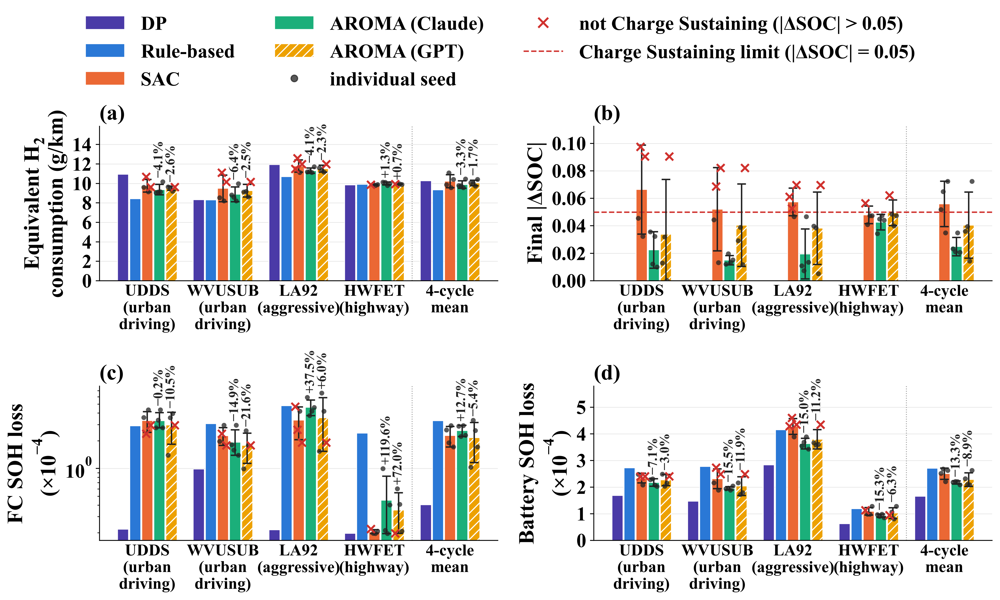

In [7]:
def _group_values(method, key, group):
    # one value per seed for this method/metric/group
    if group == 'Mean':
        return PS[PS.method == method][key].values
    return M[(M.method == method) & (M.cycle == group)][key].values


def _group_noncs(method, group):
    # True per seed (same order as _group_values) when that seed is not charge sustaining on that cycle;
    # never in the 4-cycle mean group (CS is a per-cycle property)
    if group == 'Mean':
        return np.zeros(len(PS[PS.method == method]), dtype=bool)
    return (M[(M.method == method) & (M.cycle == group)].adsoc > CS_TOL).values


PERF_TICK_STEP = {'eq': 2, 'adsoc': 0.02, 'bt': 1}  # tick spacing of the original (small-font) figure
PERF_YLABEL = {'eq': 'Equivalent H$_2$\nconsumption (g/km)', 'fc': 'FC SOH loss\n($\\times10^{-4}$)',
               'bt': 'Battery SOH loss\n($\\times10^{-4}$)'}  # two lines: the larger text is taller than a panel


def performance_figure():
    with plt.rc_context(BOLD_RC):
        groups = CYCLES + ['Mean']
        fig, axes = plt.subplots(2, 2, figsize=(13, 7.8))
        width = 0.8 / len(METHODS)
        for ax, (key, ylabel, scale, log) in zip(axes.ravel(), METRICS):
            tops = {}
            for j, m in enumerate(METHODS):
                st = STYLE[m]
                for gi, g in enumerate(groups):
                    v = _group_values(m, key, g) * scale
                    x = gi + (j - (len(METHODS) - 1) / 2) * width
                    mean = v.mean()
                    ax.bar(x, mean, width * 0.9, color=st['color'], hatch=st['hatch'], edgecolor='white', linewidth=0.6, zorder=2)
                    top = mean
                    if len(v) > 1:
                        sd = v.std(ddof=1)
                        lower = min(sd, mean - v.min()) if log else sd  # a log axis cannot show mean - std <= 0
                        ax.errorbar(x, mean, yerr=[[lower], [sd]], color=INK, linewidth=1.3, capsize=4, capthick=1.3, zorder=4)
                        jit = np.linspace(-0.28, 0.28, len(v)) * width
                        bad = _group_noncs(m, g)
                        ax.scatter((x + jit)[~bad], v[~bad], s=20, color=INK, alpha=0.75, linewidths=0, zorder=5)
                        ax.scatter((x + jit)[bad], v[bad], s=50, marker='x', color=NONCS_COLOR, linewidths=1.8, zorder=6)
                        top = max(v.max(), mean + sd)
                    tops[(m, g)] = top
            sac = {g: (_group_values('SAC', key, g) * scale).mean() for g in groups}
            crowded = len(SEEDED) > 2  # several proposers: one upright label per bar instead of a shared row
            for m in (SEEDED[1:] if key != 'adsoc' else []):  # a relative change of a near-zero |dSOC| is not informative
                j = METHODS.index(m)
                for gi, g in enumerate(groups):
                    x = gi + (j - (len(METHODS) - 1) / 2) * width
                    change = ((_group_values(m, key, g) * scale).mean() / sac[g] - 1) * 100
                    top = tops[(m, g)] if crowded else max(tops[(s, g)] for s in SEEDED)
                    ax.annotate(f'{change:+.1f}%'.replace('-', '−'), (x, top), xytext=(0, 4), textcoords='offset points',
                                ha='center', va='bottom', fontsize=12 if crowded else 14, rotation=90 if crowded else 0, color=INK)
            if key == 'adsoc':
                # labelled in the legend: an in-axes label is hidden behind the bars and crosses of every cycle
                ax.axhline(CS_TOL, color=NONCS_COLOR, linewidth=1.3, linestyle='--', zorder=3)
            if log:
                ax.set_yscale('log')
            else:
                ax.set_ylim(0, ax.get_ylim()[1] * (1.2 if crowded and key != 'adsoc' else 1.08))
                ax.yaxis.set_major_locator(MultipleLocator(PERF_TICK_STEP[key]))
            ax.axvline(len(CYCLES) - 0.5, color='0.6', linewidth=0.8, linestyle=':')
            ax.set_xticks(range(len(groups)))
            ax.set_xticklabels([f'{c}\n({CYCLE_CLASS[c]})'.replace(' ', '\n') for c in CYCLES] + ['4-cycle\nmean'], fontsize=15)
            ax.set_ylabel(PERF_YLABEL.get(key, ylabel))
            ax.grid(False, axis='x')
            ax.tick_params(axis='x', length=0)
        handles = [Patch(facecolor=STYLE[m]['color'], hatch=STYLE[m]['hatch'], edgecolor='white', label=m) for m in METHODS]
        handles.append(Line2D([], [], marker='o', color=INK, linestyle='none', markersize=6, alpha=0.75, label='individual seed'))
        handles.append(Line2D([], [], marker='x', color=NONCS_COLOR, linestyle='none', markersize=9, markeredgewidth=1.8, label=f'not Charge Sustaining (|$\\Delta$SOC| > {CS_TOL})'))
        handles.append(Line2D([], [], color=NONCS_COLOR, linewidth=1.3, linestyle='--', label=f'Charge Sustaining limit (|$\\Delta$SOC| = {CS_TOL})'))
        fig.legend(handles=handles, ncol=3, loc='upper center', bbox_to_anchor=(0.5, 1.0), frameon=False)
        for ax, tag in zip(axes.ravel(), 'abcd'):
            ax.set_title(f'({tag})', loc='left')
        fig.tight_layout(rect=(0, 0, 1, 0.86))
        save_fig('performance_by_cycle', fig)
        plt.show()


performance_figure()

## Figure 1b — charge sustaining and the SOC correction

Equivalent H$_2$ = raw H$_2$ + SOC correction. A rollout that ends above SOC0 gets a negative correction (the energy left in the
battery is credited as hydrogen saved), so a policy that does not hold charge — in these runs mostly the SAC baselines of seeds 41
and 81, which end 0.06–0.10 high on most cycles — gets an equivalent H$_2$ figure that rests on the conversion of stored energy
rather than on fuel actually saved, and is flattered against the charge-sustaining AROMA policies. Fuel comparisons with such a
baseline are therefore not like-for-like.

(a) Final ΔSOC vs equivalent H$_2$ for every seeded rollout, one panel per cycle; the shaded band is charge sustaining
(|ΔSOC| ≤ `CS_TOL`), DP and rule-based are the reference marks. (b) The SOC correction (equivalent − raw, g/km) against ΔSOC: its
size grows with the drift, i.e. the further off CS, the more of the fuel number is credit.

The table `CS_MATCHED` repeats the 4-cycle fuel comparison on the **CS-matched cycles** only: for each seed, the cycles on which
SAC and every AROMA backbone end within `CS_TOL`, so no method is compared on a credited number. `n_cycles` is how many
(seed, cycle) pairs remain.

[fig] multi_seed_v3cat__cs_check_soc_correction -> paper_figures/


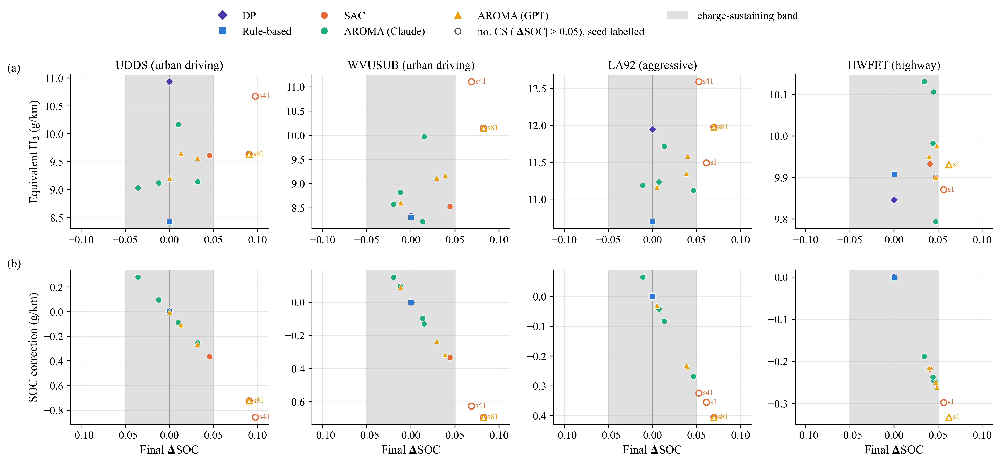

CS-matched (seed, cycle) pairs: ['s1 UDDS', 's1 WVUSUB', 's41 HWFET', 's61 UDDS', 's61 WVUSUB', 's61 LA92', 's61 HWFET', 's81 HWFET']
non-CS rollouts: ['SAC s1 LA92 dSOC +0.061', 'SAC s1 HWFET dSOC +0.056', 'SAC s41 UDDS dSOC +0.098', 'SAC s41 WVUSUB dSOC +0.069', 'SAC s41 LA92 dSOC +0.053', 'SAC s81 UDDS dSOC +0.090', 'SAC s81 WVUSUB dSOC +0.082', 'SAC s81 LA92 dSOC +0.070', 'AROMA (GPT) s1 HWFET dSOC +0.062', 'AROMA (GPT) s81 UDDS dSOC +0.090', 'AROMA (GPT) s81 WVUSUB dSOC +0.082', 'AROMA (GPT) s81 LA92 dSOC +0.070']


,eq all cycles,eq CS-matched,raw CS-matched,non-CS rollouts,n_cycles,eq all cycles vs SAC (%),eq CS-matched vs SAC (%)
SAC,10.234,9.531,9.785,8.0,8.0,0.000,0.000
AROMA (Claude),9.895,9.527,9.648,0.0,8.0,-3.312,-0.042
AROMA (GPT),10.059,9.697,9.822,4.0,8.0,-1.710,1.740


In [8]:
def cs_check_figure():
    M['soc_corr'] = M['eq'] - M['raw']
    fig, axes = plt.subplots(2, len(CYCLES), figsize=(3.5 * len(CYCLES), 6.4), sharex='row')
    lim = max(M.adsoc.max(), CS_TOL) * 1.15
    for j, c in enumerate(CYCLES):
        for r, (key, ylabel) in enumerate([('eq', 'Equivalent H$_2$ (g/km)'), ('soc_corr', 'SOC correction (g/km)')]):
            ax = axes[r, j]
            ax.axvspan(-CS_TOL, CS_TOL, color='0.88', zorder=0, label='charge sustaining')
            ax.axvline(0, color='0.6', linewidth=0.7, zorder=1)
            for m in METHODS:
                d = M[(M.method == m) & (M.cycle == c)]
                st = STYLE[m]
                bad = d.adsoc > CS_TOL
                ax.scatter(d.dsoc[~bad], d[key][~bad], s=34, marker=st['marker'], color=st['color'], edgecolors='white',
                           linewidths=0.5, zorder=3)
                ax.scatter(d.dsoc[bad], d[key][bad], s=34, marker=st['marker'], facecolors='white', edgecolors=st['color'],
                           linewidths=1.3, zorder=3)
                for _, p in d[bad].iterrows():
                    ax.annotate(f's{int(p.seed)}', (p.dsoc, p[key]), xytext=(4, 0), textcoords='offset points', fontsize=8,
                                va='center', color=st['color'])
            ax.set_xlim(-lim, lim)
            if r == 0:
                ax.set_title(f'{c} ({CYCLE_CLASS[c]})', fontsize=12)
            else:
                ax.set_xlabel('Final $\\Delta$SOC')
            if j == 0:
                ax.set_ylabel(ylabel)
    for ax, tag in zip(axes[:, 0], 'ab'):
        ax.annotate(f'({tag})', (-0.32, 1.02), xycoords='axes fraction', fontsize=12)
    handles = [Line2D([], [], marker=STYLE[m]['marker'], color=STYLE[m]['color'], linestyle='none', markersize=6, label=m) for m in METHODS]
    handles += [Line2D([], [], marker='o', markerfacecolor='white', color='0.3', linestyle='none', markersize=6,
                       label=f'not CS (|$\\Delta$SOC| > {CS_TOL}), seed labelled'),
                Patch(facecolor='0.88', label='charge-sustaining band')]
    fig.legend(handles=handles, ncol=4, loc='upper center', bbox_to_anchor=(0.5, 1.02), frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    save_fig('cs_check_soc_correction', fig)
    plt.show()


def cs_matched_table():
    # cycles where SAC and every AROMA backbone of the seed are charge sustaining
    s = M[M.method.isin(SEEDED)]
    ok = s.assign(ok=s.adsoc <= CS_TOL).groupby(['seed', 'cycle'], observed=True).ok.all()
    keep = ok[ok].index
    rows = {}
    for m in SEEDED:
        d = s[s.method == m].set_index(['seed', 'cycle'])
        dm = d.loc[d.index.intersection(keep)]
        rows[m] = {'eq all cycles': d['eq'].mean(), 'eq CS-matched': dm['eq'].mean(),
                   'raw CS-matched': dm['raw'].mean(), 'non-CS rollouts': int((d.adsoc > CS_TOL).sum()),
                   'n_cycles': len(dm)}
    t = pd.DataFrame(rows).T
    for k in ['eq all cycles', 'eq CS-matched']:
        t[f'{k} vs SAC (%)'] = (t[k] / t.loc['SAC', k] - 1) * 100
    print('CS-matched (seed, cycle) pairs:', [f's{int(a)} {b}' for a, b in keep])
    print('non-CS rollouts:', [f'{r.method} s{int(r.seed)} {r.cycle} dSOC {r.dsoc:+.3f}'
                               for r in M[M.adsoc > CS_TOL].itertuples()])
    if SAVE_FIGS:
        t.to_csv(FIG_OUTDIR / f'{FIG_PREFIX}__cs_matched_fuel.csv')
    return t


cs_check_figure()
CS_MATCHED = cs_matched_table()
CS_MATCHED.round(3)

## Figure 2 — paired seed comparison SAC → AROMA

Change of the 4-cycle mean against the SAC baseline of the same seed, one group per seed and one bar per proposer backbone.
Fuel and SOH losses are relative changes (%); |ΔSOC| is the absolute difference because the baseline value is close to zero.
Below zero is better in every panel. The seed label gives on how many of the four cycles SAC is charge sustaining;
where it is below 4/4 the fuel change against SAC is against a credited (non-CS) baseline value (Figure 1b). `REL` holds the plotted values.
The seed-mean bar is the mean of the per-seed changes, so it differs slightly from Figure 1 and the summary table,
which report the change of the seed-mean value.

With two or more backbones the second table compares them head to head on the seeds they share: paired difference
(second − first) of the 4-cycle means and the number of seeds on which the second backbone is lower (lower is better).

[fig] multi_seed_v3cat__paired_seed_vs_sac -> paper_figures/


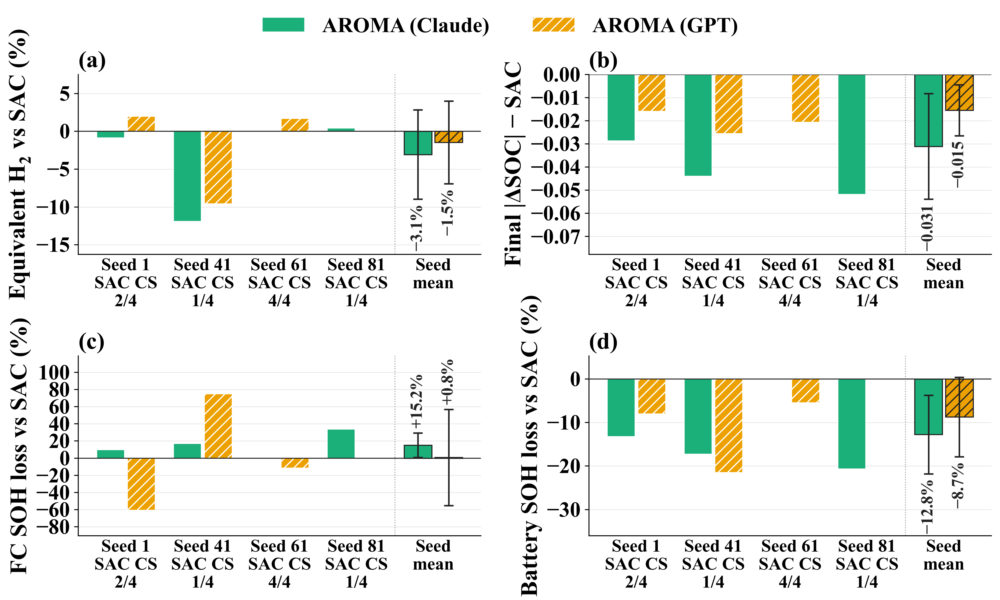

AROMA (Claude)                                AROMA (GPT)                               
                 eq     raw      fc      bt  adsoc          eq     raw      fc      bt  adsoc
seed                                                                                         
1            -0.843  -4.747   9.826 -13.184 -0.029       1.983   0.831 -60.600  -7.987 -0.016
41          -11.890 -15.657  17.063 -17.232 -0.044      -9.562 -11.209  75.118 -21.469 -0.025
61            0.000   0.000   0.000   0.000  0.000       1.706  -0.150 -11.408  -5.421 -0.021
81            0.427  -3.095  33.734 -20.638 -0.052       0.000   0.000   0.000   0.000  0.000

,Claude,GPT,GPT − Claude,change (%),GPT lower (seeds)
metric,,,,,
Eq. H2 (g/km),9.895,10.059,0.164 ± 0.148,+1.7,1/4
|dSOC|,0.025,0.041,0.016 ± 0.030,+62.6,1/4
FC SOH loss (1e-4),2.577,2.164,-0.413 ± 1.208,-16.0,3/4
Batt. SOH loss (1e-4),2.177,2.288,0.110 ± 0.312,+5.1,2/4


In [9]:
REL_KEYS = ['eq', 'raw', 'fc', 'bt']


def _vs_sac(method):
    # per-seed change of the 4-cycle mean against the same-seed SAC: % for fuel / SOH loss, difference for |dSOC|
    a = PS[PS.method == method].set_index('seed')
    s = PS[PS.method == 'SAC'].set_index('seed').loc[a.index]
    out = (a[REL_KEYS] / s[REL_KEYS] - 1) * 100
    out['adsoc'] = a['adsoc'] - s['adsoc']
    out.index = out.index.astype(int)
    return out


def rel_table():
    return pd.concat({m: _vs_sac(m) for m in SEEDED[1:]}, axis=1)


REL = rel_table()

PAIRED_PANELS = [('eq', 'Equivalent H$_2$ vs SAC (%)'), ('adsoc', 'Final |$\\Delta$SOC| $-$ SAC'),
                 ('fc', 'FC SOH loss vs SAC (%)'), ('bt', 'Battery SOH loss vs SAC (%)')]


def _fit_annotations(fig, axes, pad=0.03):
    # widen each y range so the (larger) seed-mean labels stay inside the axes instead of running into the tick labels
    for _ in range(2):
        fig.canvas.draw()
        r = fig.canvas.get_renderer()
        for ax in axes:
            lo, hi = ax.get_ylim()
            inv = ax.transData.inverted()
            for t in ax.texts:
                bb = t.get_window_extent(r)
                lo = min(lo, inv.transform((0, bb.y0))[1])
                hi = max(hi, inv.transform((0, bb.y1))[1])
            span = hi - lo
            if (lo, hi) != ax.get_ylim():
                ax.set_ylim(lo - pad * span if lo < ax.get_ylim()[0] else lo, hi + pad * span if hi > ax.get_ylim()[1] else hi)


PAIRED_TICK_STEP = {'eq': 5, 'adsoc': 0.01, 'fc': 20, 'bt': 10}  # tick spacing of the original (small-font) figure


def paired_seed_figure():
    with plt.rc_context(BOLD_RC):
        methods = SEEDED[1:]
        sac_cs = PS[PS.method == 'SAC'].set_index('seed').cs_ok
        groups = [f'Seed {s}\nSAC CS\n{int(sac_cs[s])}/{len(CYCLES)}' for s in SEEDS] + ['Seed\nmean']
        fig, axes = plt.subplots(2, 2, figsize=(12, 7.2))
        width = 0.8 / len(methods)
        for ax, (key, ylabel) in zip(axes.ravel(), PAIRED_PANELS):
            for j, m in enumerate(methods):
                st, v = STYLE[m], REL[m][key].reindex(SEEDS)
                x = np.arange(len(SEEDS)) + (j - (len(methods) - 1) / 2) * width
                ax.bar(x, v.values, width * 0.9, color=st['color'], hatch=st['hatch'], edgecolor='white', linewidth=0.6, zorder=2)
                xm, mean = len(SEEDS) + (j - (len(methods) - 1) / 2) * width, v.mean()
                ax.bar(xm, mean, width * 0.9, color=st['color'], hatch=st['hatch'], edgecolor=INK, linewidth=0.9, zorder=2)
                sd = v.std(ddof=1) if v.count() > 1 else 0.0
                if v.count() > 1:
                    ax.errorbar(xm, mean, yerr=sd, color=INK, linewidth=1.3, capsize=4, capthick=1.3, zorder=4)
                # seed-mean value, upright past the whisker on the bar's own side of zero
                label, up = (f'{mean:+.3f}' if key == 'adsoc' else f'{mean:+.1f}%'), mean > 0
                ax.annotate(label.replace('-', '−'), (xm, mean + sd if up else mean - sd), xytext=(0, 4 if up else -4),
                            textcoords='offset points', ha='center', va='bottom' if up else 'top', fontsize=14, rotation=90, color=INK)
            ax.axhline(0, color=INK, linewidth=0.8, zorder=3)
            ax.axvline(len(SEEDS) - 0.5, color='0.6', linewidth=0.8, linestyle=':')
            ax.set_xticks(range(len(groups)))
            ax.set_xticklabels(groups, fontsize=15)
            ax.set_ylabel(ylabel)
            ax.margins(y=0.22)
            ax.yaxis.set_major_locator(MultipleLocator(PAIRED_TICK_STEP[key]))
            ax.grid(False, axis='x')
            ax.tick_params(axis='x', length=0)
        handles = [Patch(facecolor=STYLE[m]['color'], hatch=STYLE[m]['hatch'], edgecolor='white', label=m) for m in methods]
        fig.legend(handles=handles, ncol=len(handles), loc='upper center', bbox_to_anchor=(0.5, 1.0), frameon=False)
        for ax, tag in zip(axes.ravel(), 'abcd'):
            ax.set_title(f'({tag})', loc='left')
        fig.tight_layout(rect=(0, 0, 1, 0.95))
        _fit_annotations(fig, axes.ravel())
        save_fig('paired_seed_vs_sac', fig)
        plt.show()


def head_to_head(first, second):
    # paired comparison of two proposers on the seeds they share (4-cycle means, lower is better)
    a = PS[PS.method == AROMA_LABEL[first]].set_index('seed')
    b = PS[PS.method == AROMA_LABEL[second]].set_index('seed')
    seeds = a.index.intersection(b.index)
    rows = []
    for key, label, scale, digits in TABLE_SPEC:
        d = (b.loc[seeds, key] - a.loc[seeds, key]) * scale
        rows.append({'metric': label, first: f'{a.loc[seeds, key].mean() * scale:.{digits}f}',
                     second: f'{b.loc[seeds, key].mean() * scale:.{digits}f}',
                     f'{second} − {first}': _fmt(d.mean(), d.std(ddof=1) if len(d) > 1 else np.nan, 1.0, digits),
                     'change (%)': f'{(b.loc[seeds, key].mean() / a.loc[seeds, key].mean() - 1) * 100:+.1f}',
                     f'{second} lower (seeds)': f'{int((d < 0).sum())}/{len(d)}'})
    return pd.DataFrame(rows).set_index('metric')


paired_seed_figure()
display(REL.round(3))
H2H = {(a, b): head_to_head(a, b) for i, a in enumerate(LLMS) for b in LLMS[i + 1:]}
for (a, b), tab in H2H.items():
    if SAVE_FIGS:
        tab.to_csv(FIG_OUTDIR / f'{FIG_PREFIX}__head_to_head_{a}_vs_{b}.csv')
    display(tab)

## Figure 3 — representative seed: operating points on the FC efficiency curve

One panel per method (rows) and cycle (columns). The grey line is the FC system efficiency map against stack power; each dot
is one FC-on second of the rollout (`P_fc`, `fce_eff`). The label gives the trip-average operating efficiency
(FC net energy over H$_2$ energy, the same value used in the equivalent-fuel conversion) and the FC-on time share.

[fig] multi_seed_v3cat__fc_efficiency_map_seed41 -> paper_figures/


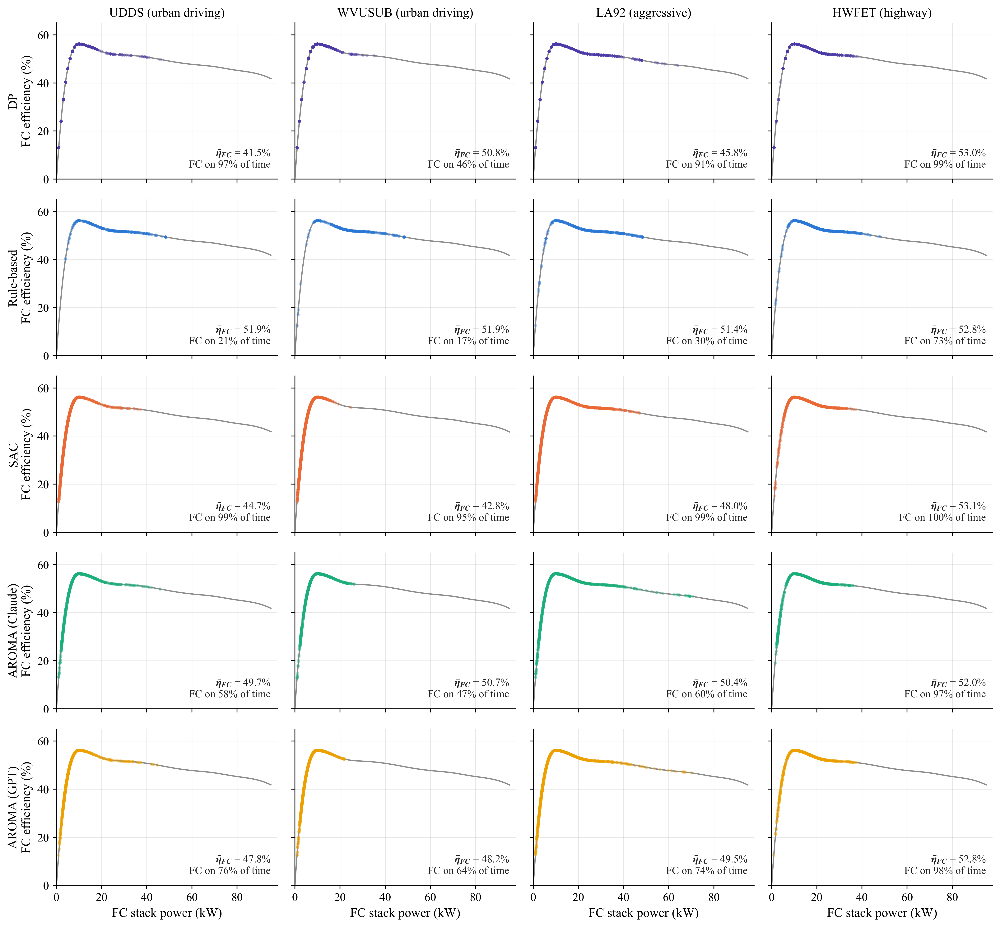

In [10]:
def load_trace(path):
    # trace paths in the tables are repo-relative; traces ship in the release bundle
    d = scio.loadmat(REPO / path)
    return {k: np.asarray(v, dtype=float).reshape(-1) for k, v in d.items() if not k.startswith('__')}


def _trace_path(method, cycle, seed=None):
    g = M[(M.method == method) & (M.cycle == cycle) & ((M.seed == seed) if seed is not None else M.seed.isna())]
    assert len(g) == 1, (method, cycle, seed, len(g))
    return g.trace.iloc[0]


def rep_traces(cycle, llms=None):
    # SAC is iter1 of the seed; it is the same baseline actor in every run of the seed
    tr = {'DP': load_trace(_trace_path('DP', cycle)), 'Rule-based': load_trace(_trace_path('Rule-based', cycle)),
          'SAC': load_trace(_trace_path('SAC', cycle, REP_SEED))}
    for llm in (REP_LLMS if llms is None else llms):
        tr[AROMA_LABEL[llm]] = load_trace(_trace_path(AROMA_LABEL[llm], cycle, REP_SEED))
    return tr


TRACE_ORDER = ['DP', 'Rule-based', 'SAC'] + [AROMA_LABEL[l] for l in REP_LLMS]

FC_MAP_DIR = REPO / 'project-data' / 'FCHEV_data'
_p = np.asarray(scio.loadmat(FC_MAP_DIR / 'P_fc_stack_nexo.mat')['P_fc_stack'], dtype=float).reshape(-1)
_e = np.asarray(scio.loadmat(FC_MAP_DIR / 'Eff_fc_nexo.mat')['Eff_fc'], dtype=float).reshape(-1)
_ok = np.isfinite(_p) & np.isfinite(_e)
_order = np.argsort(_p[_ok])
FC_CURVE_P, FC_CURVE_EFF = _p[_ok][_order], _e[_ok][_order] * 100.0


def fc_operating_points(d):
    # FC-on samples: stack power (kW), system efficiency (%), and the trip-average operating efficiency (%)
    p, eff = d['P_fc'], d['fce_eff']
    n = min(len(p), len(eff))
    p, eff = p[:n], eff[:n]
    on = np.isfinite(p) & np.isfinite(eff) & (p > 0.0) & (eff > 0.0)
    w = d['P_fce'][:n][on] if 'P_fce' in d else p[on]  # net power weights the trip average
    trip_eff = 100.0 * w.sum() / (w / eff[on]).sum()
    return p[on], eff[on] * 100.0, trip_eff, 100.0 * on.sum() / n


def fc_efficiency_map_figure():
    data = {c: rep_traces(c) for c in CYCLES}
    fig, axes = plt.subplots(len(TRACE_ORDER), len(CYCLES), figsize=(3.3 * len(CYCLES), 2.45 * len(TRACE_ORDER)),
                             sharex=True, sharey=True)
    x_max = max(FC_CURVE_P.max(), max(d['P_fc'].max() for c in CYCLES for d in data[c].values())) * 1.03
    for i, m in enumerate(TRACE_ORDER):
        for j, c in enumerate(CYCLES):
            ax = axes[i, j]
            p, eff, trip_eff, on_pct = fc_operating_points(data[c][m])
            ax.plot(FC_CURVE_P, FC_CURVE_EFF, color='0.55', linewidth=1.2, zorder=1)
            ax.scatter(p, eff, s=9, color=STYLE[m]['color'], alpha=0.35, linewidths=0, zorder=2)
            ax.text(0.97, 0.06, f'$\\bar{{\\eta}}_{{FC}}$ = {trip_eff:.1f}%\nFC on {on_pct:.0f}% of time', transform=ax.transAxes,
                    ha='right', va='bottom', fontsize=10, color=INK)
            ax.set_xlim(0, x_max)
            ax.set_ylim(0, 65)
            if i == 0:
                ax.set_title(f'{c} ({CYCLE_CLASS[c]})', fontsize=12)
            if j == 0:
                ax.set_ylabel(f'{m}\nFC efficiency (%)')
            if i == len(TRACE_ORDER) - 1:
                ax.set_xlabel('FC stack power (kW)')
    fig.tight_layout()
    fig.align_ylabels(axes[:, 0])
    save_fig(f'fc_efficiency_map_seed{REP_SEED}', fig)
    plt.show()


fc_efficiency_map_figure()

## Figures S1–S4 — FC operating points on the efficiency curve, one figure per cycle

Seed and policy shown: `REP_SEED`; AROMA-SAC is the `SUPP_LLM` backbone's adopted iteration for that seed (`PICKS`, printed below).
Baseline SAC is iteration 1 of the same seed. DP and rule-based do not depend on the seed.

One 2 × 2 figure per evaluation cycle, titled with the cycle name: (a) DP, (b) rule-based, (c) baseline SAC, (d) AROMA-SAC. The grey line is the FC system
efficiency against stack power; each dot is one FC-on second of the rollout. The label gives the trip-average operating efficiency
and the FC-on time share.

Figures S1-S4: seed 41, AROMA-SAC = Claude run iteration 5
[fig] multi_seed_v3cat__figS1_fc_operating_points_seed41_UDDS -> paper_figures/


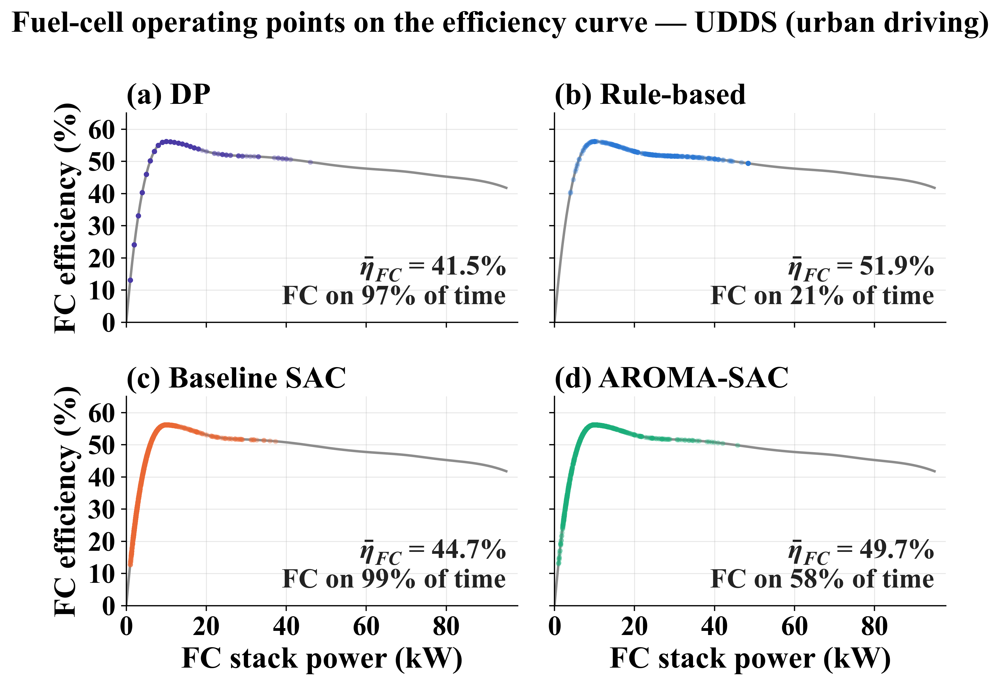

[fig] multi_seed_v3cat__figS2_fc_operating_points_seed41_WVUSUB -> paper_figures/


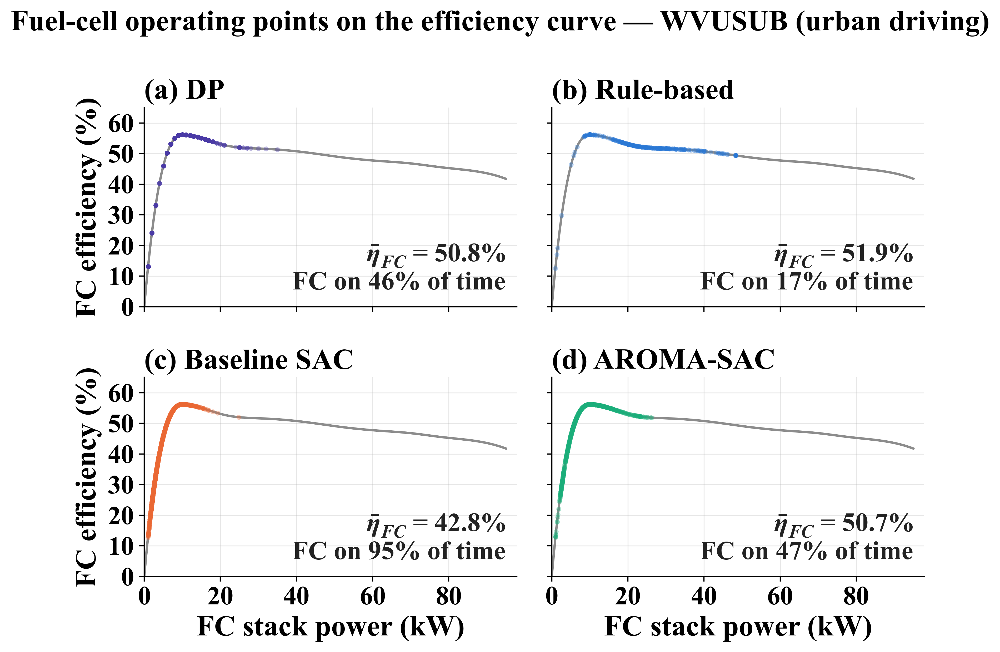

[fig] multi_seed_v3cat__figS3_fc_operating_points_seed41_LA92 -> paper_figures/


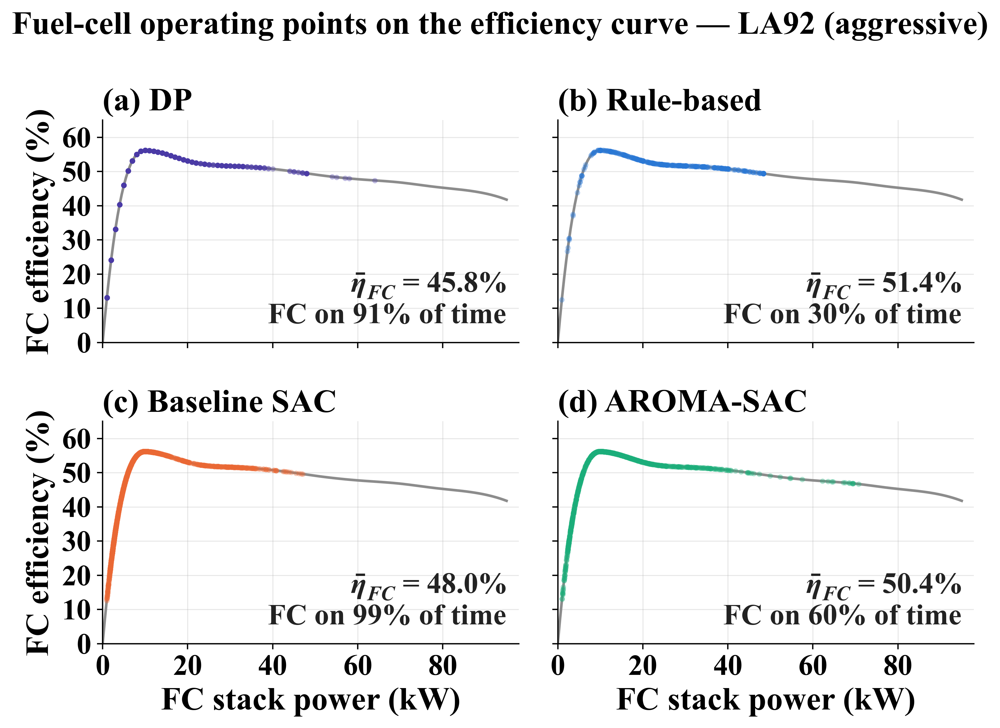

[fig] multi_seed_v3cat__figS4_fc_operating_points_seed41_HWFET -> paper_figures/


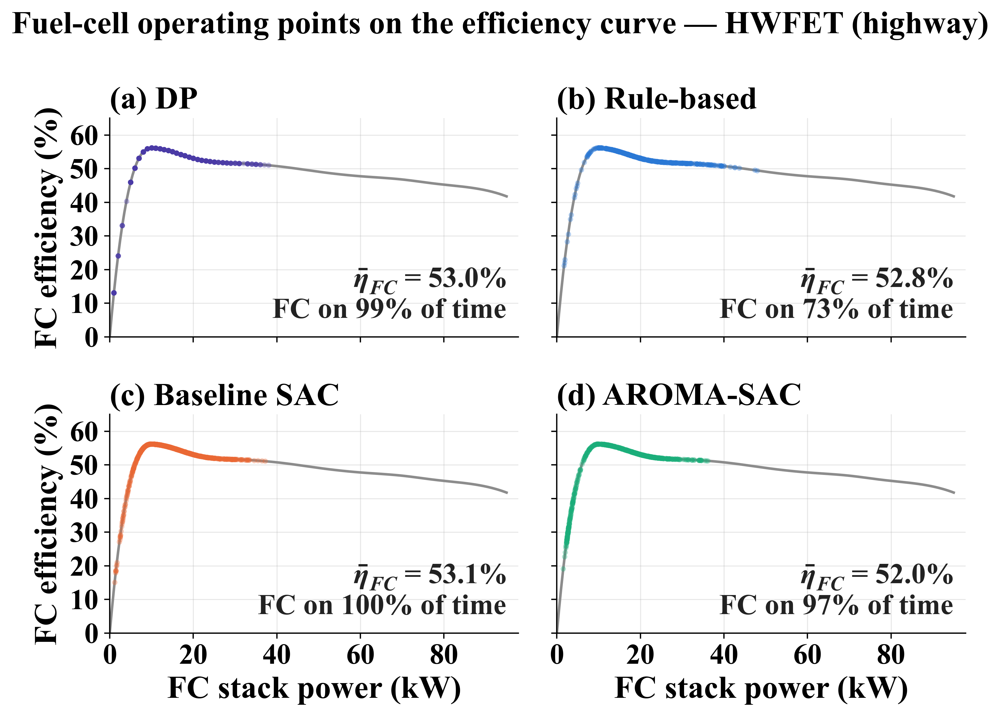

In [11]:
SUPP_PANELS = [('DP', 'DP'), ('Rule-based', 'Rule-based'), ('SAC', 'Baseline SAC'), (AROMA_LABEL[SUPP_LLM], 'AROMA-SAC')]
print(f'Figures S1-S4: seed {REP_SEED}, AROMA-SAC = {SUPP_LLM} run iteration {PICKS[SUPP_LLM][REP_SEED]}')


def fc_operating_points_figure(cycle, number):
    with plt.rc_context(BOLD_RC):
        tr = rep_traces(cycle, [SUPP_LLM])
        fig, axes = plt.subplots(2, 2, figsize=(8.6, 6.4), sharex=True, sharey=True)
        for ax, tag, (m, title) in zip(axes.ravel(), 'abcd', SUPP_PANELS):
            p, eff, trip_eff, on_pct = fc_operating_points(tr[m])
            ax.plot(FC_CURVE_P, FC_CURVE_EFF, color='0.55', linewidth=1.6, zorder=1)
            ax.scatter(p, eff, s=11, color=STYLE[m]['color'], alpha=0.35, linewidths=0, zorder=2)
            ax.text(0.97, 0.06, f'$\\bar{{\\eta}}_{{FC}}$ = {trip_eff:.1f}%\nFC on {on_pct:.0f}% of time', transform=ax.transAxes,
                    ha='right', va='bottom', fontsize=18, color=INK)
            ax.set_xlim(0, FC_CURVE_P.max() * 1.03)
            ax.set_ylim(0, 65)
            ax.xaxis.set_major_locator(MultipleLocator(20))  # original tick spacing
            ax.yaxis.set_major_locator(MultipleLocator(10))
            ax.set_title(f'({tag}) {title}', loc='left')
        for ax in axes[-1]:
            ax.set_xlabel('FC stack power (kW)')
        for ax in axes[:, 0]:
            ax.set_ylabel('FC efficiency (%)')
        fig.suptitle(f'Fuel-cell operating points on the efficiency curve — {cycle} ({CYCLE_CLASS[cycle]})', fontsize=20)
        fig.tight_layout()
        save_fig(f'figS{number}_fc_operating_points_seed{REP_SEED}_{cycle}', fig)
        plt.show()


for k, c in enumerate(CYCLES, start=1):
    fc_operating_points_figure(c, k)

## Economic translation — what the fuel and wear differences mean in use

The per-cycle fuel and SOH numbers are converted to a vehicle in service. Assumptions (constants in the configuration cell):

- Driving mix: the same distance on each of the four cycles, so fuel per km is the "4-cycle mean" of the tables above.
- Component life: the SOH loss per km is extrapolated linearly to end of life, 10% voltage loss for the FC (`FC_EOL_LOSS`,
  the limit of the plant's degradation model) and 20% capacity loss for the battery (`BATT_EOL_LOSS`). Hours follow from the
  average speed of the mix, years from `ANNUAL_KM`.
- Hydrogen cost: hydrogen at `H2_PRICE`.
- Degradation cost: the part of the FC system (`FC_NET_KW` × `FC_COST_PER_KW`, net system output, not the 95 kW stack) and of the battery pack (`BATT_KWH` ×
  `BATT_COST_PER_KWH`) used up by the wear of the distance driven, i.e. component cost divided by component life.
  The hardware is the same for every controller; the controller changes how fast it is consumed. No discounting.
- Seeds: bars and tables use the seed-mean fuel and wear rates (so a life is the life at the mean wear rate, not the
  mean of the per-seed lives); dots are the individual seeds.
- Battery life is short in absolute terms (about 12–19 thousand km for every method, DP included): the pack is a 1.56 kWh
  power buffer cycled continuously, and the capacity-loss model applies a sub-linear throughput law per 1 s step. It is
  counted in the degradation cost because both the FC and the battery are worn by the power split; read the battery part as a
  comparison between controllers more than as a replacement interval.

In [12]:
# Driving mix: the same distance on each of the four cycles, so the fuel per km equals the "4-cycle mean" used above.
DIST = ref[ref.method == 'DP'].set_index('cycle').distance_km.loc[CYCLES]
SECONDS = ref[ref.method == 'DP'].set_index('cycle').steps.loc[CYCLES].astype(float)  # 1 s steps
HOURS_PER_KM = (SECONDS / DIST).mean() / 3600.0
FC_COST = FC_NET_KW * FC_COST_PER_KW
BATT_COST = BATT_KWH * BATT_COST_PER_KWH



def econ_tables(m):
    # per-(method, seed) rates, their economics, and the economics at the seed-mean rates
    _m = m.assign(seed=m.seed.fillna(-1), dist=m.cycle.map(DIST).astype(float))
    _m['fc_km'], _m['bt_km'] = _m.fc / _m.dist, _m.bt / _m.dist
    rate = _m.groupby(['method', 'seed'], observed=True)[['eq', 'fc_km', 'bt_km']].mean().reset_index()
    return rate, economics(rate), economics(rate.groupby('method')[['eq', 'fc_km', 'bt_km']].mean().loc[METHODS])


def economics(rate):
    # rate: eq (g/km), fc_km and bt_km (SOH loss per km); works on the per-seed frame and on the seed-mean frame
    e = rate.copy()
    e['fc_life_km'] = FC_EOL_LOSS / e.fc_km
    e['fc_life_h'] = e.fc_life_km * HOURS_PER_KM
    e['fc_life_yr'] = e.fc_life_km / ANNUAL_KM
    e['h2_cost'] = e['eq'] / 1000.0 * H2_PRICE * 100.0  # USD per 100 km
    e['bt_life_km'] = BATT_EOL_LOSS / e.bt_km
    e['bt_life_yr'] = e.bt_life_km / ANNUAL_KM
    e['fc_cost'] = FC_COST / e.fc_life_km * 100.0    # FC system used up, USD per 100 km
    e['bt_cost'] = BATT_COST / e.bt_life_km * 100.0  # battery pack used up, USD per 100 km
    e['deg_cost'] = e.fc_cost + e.bt_cost
    e['total_cost'] = e.h2_cost + e.deg_cost
    return e


RATE, ECON, ECON_MEAN = econ_tables(M)  # ECON: one row per (method, seed); ECON_MEAN: at the seed-mean rates
print(f'mix: {1 / HOURS_PER_KM:.1f} km/h average speed; FC system {FC_COST:,.0f} USD, battery pack {BATT_COST:,.0f} USD; '
      f'DOE {DOE_FC_LIFE_H:,.0f} h = {DOE_FC_LIFE_H / HOURS_PER_KM:,.0f} km')
ECON_MEAN[['eq', 'fc_life_km', 'fc_life_h', 'fc_life_yr', 'bt_life_km', 'h2_cost', 'fc_cost', 'bt_cost', 'deg_cost', 'total_cost']].round(2)

mix: 36.8 km/h average speed; FC system 6,080 USD, battery pack 758 USD; DOE 8,000 h = 294,361 km


,eq,fc_life_km,fc_life_h,fc_life_yr,bt_life_km,h2_cost,fc_cost,bt_cost,deg_cost,total_cost
method,,,,,,,,,,
DP,10.27,31684.01,861.09,2.11,16564.71,7.19,19.19,4.58,23.77,30.95
Rule-based,9.33,4202.94,114.23,0.28,10040.68,6.53,144.66,7.55,152.21,158.75
SAC,10.23,5774.00,156.92,0.38,10984.40,7.16,105.30,6.90,112.20,119.37
AROMA (Claude),9.89,5273.59,143.32,0.35,12631.14,6.93,115.29,6.00,121.29,128.22
AROMA (GPT),10.06,6209.36,168.75,0.41,12035.99,7.04,97.92,6.30,104.22,111.26


## Figure 4 — total operating cost per 100 km

Hydrogen cost (solid) plus degradation cost (FC cross-hatched, battery dotted) at the seed-mean rates; the whisker is the seed
standard deviation of the total and the dots are the seeds. The number above each bar is the total, with the change against
SAC for AROMA. The y axis is broken only when the rule-based total exceeds twice the largest total of the other methods.

[fig] multi_seed_v3cat__driving_cost_per_100km -> paper_figures/


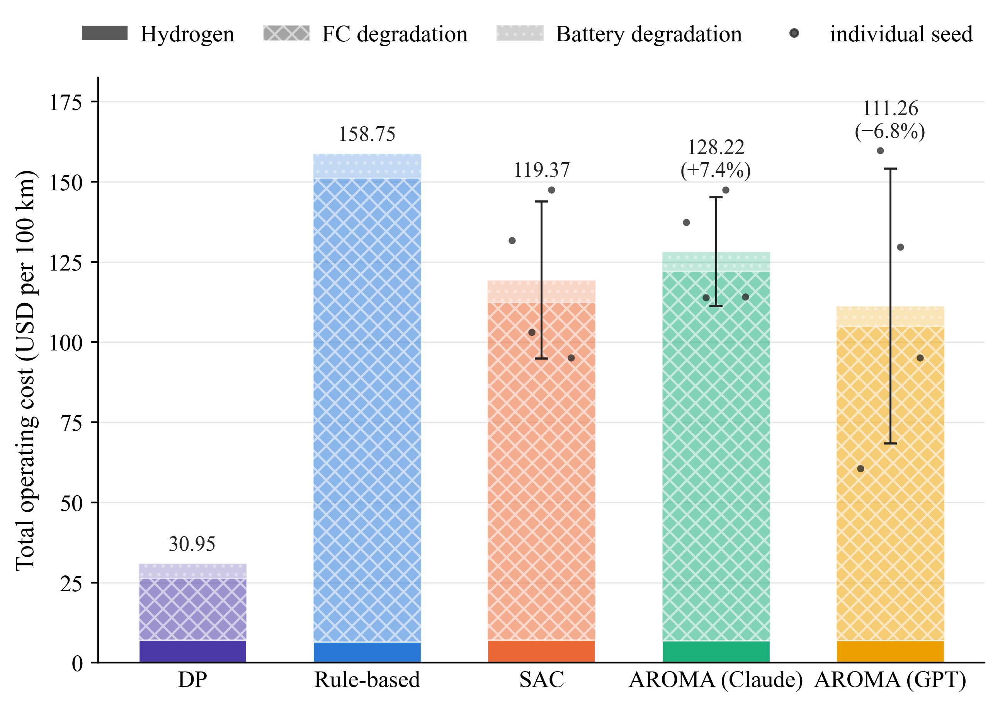

In [13]:
def _pct(v):
    return f'{v:+.1f}%'.replace('-', '−')


def cost_figure():
    # Broken y axis only when the rule-based total exceeds twice the largest total of every other method.
    tot = ECON_MEAN.total_cost
    others = tot.drop('Rule-based').max()
    broken = tot.max() > 2.0 * others
    low_top = others * 1.45 if broken else tot.max() * 1.15
    if broken:
        fig, (hi, lo) = plt.subplots(2, 1, figsize=(7.4, 5.4), sharex=True, gridspec_kw=dict(height_ratios=[1, 3.2], hspace=0.06))
        panels = [hi, lo]
    else:
        fig, lo = plt.subplots(figsize=(7.4, 4.8))
        panels = [lo]
    for ax in panels:
        for j, m in enumerate(METHODS):
            st, r = STYLE[m], ECON_MEAN.loc[m]
            ax.bar(j, r.h2_cost, 0.62, color=st['color'], edgecolor='white', linewidth=0.6, zorder=2)
            ax.bar(j, r.fc_cost, 0.62, bottom=r.h2_cost, color=st['color'], alpha=0.55, hatch='xxx', edgecolor='white',
                   linewidth=0.6, zorder=2)
            ax.bar(j, r.bt_cost, 0.62, bottom=r.h2_cost + r.fc_cost, color=st['color'], alpha=0.28, hatch='...',
                   edgecolor='white', linewidth=0.6, zorder=2)
            v = ECON[ECON.method == m].total_cost.values
            if len(v) > 1:
                ax.errorbar(j, r.total_cost, yerr=v.std(ddof=1), color=INK, linewidth=0.9, capsize=3, zorder=4)
                ax.scatter(j + np.linspace(-0.17, 0.17, len(v)), v, s=11, color=INK, alpha=0.75, linewidths=0, zorder=5)
        ax.grid(False, axis='x')
        ax.tick_params(axis='x', length=0)
    for j, m in enumerate(METHODS):
        r = ECON_MEAN.loc[m]
        v = ECON[ECON.method == m].total_cost.values
        top = max(v.max(), r.total_cost + v.std(ddof=1)) if len(v) > 1 else r.total_cost
        label = f'{r.total_cost:.2f}'
        if m in SEEDED[1:]:
            label += f'\n({_pct((r.total_cost / tot["SAC"] - 1) * 100)})'
        ax = panels[0] if (broken and top > low_top) else lo
        ax.annotate(label, (j, top), xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontsize=10, color=INK)
    lo.set_ylim(0, low_top)
    if broken:
        hi.set_ylim(tot.max() * 0.78, tot.max() * 1.22)
        hi.spines['bottom'].set_visible(False)
        kw = dict(marker=[(-1, -0.5), (1, 0.5)], markersize=9, linestyle='none', color=INK, mec=INK, mew=0.9, clip_on=False)
        hi.plot([0], [0], transform=hi.transAxes, **kw)
        lo.plot([0], [1], transform=lo.transAxes, **kw)
    lo.set_xticks(range(len(METHODS)))
    lo.set_xticklabels(METHODS)
    lo.set_ylabel('Total operating cost (USD per 100 km)')
    handles = [Patch(facecolor='0.35', edgecolor='white', label='Hydrogen'),
               Patch(facecolor='0.35', alpha=0.55, hatch='xxx', edgecolor='white', label='FC degradation'),
               Patch(facecolor='0.35', alpha=0.28, hatch='...', edgecolor='white', label='Battery degradation'),
               Line2D([], [], marker='o', color=INK, linestyle='none', markersize=3.5, alpha=0.75, label='individual seed')]
    fig.legend(handles=handles, ncol=4, columnspacing=1.2, handletextpad=0.5, loc='upper center', bbox_to_anchor=(0.5, 1.0), frameon=False)
    fig.subplots_adjust(top=0.9)
    save_fig('driving_cost_per_100km', fig)
    plt.show()


cost_figure()

### Figure 4b and table — hydrogen cost and degradation cost separately

The two parts of Figure 4 on their own axes, both in USD per 100 km: (a) hydrogen cost, the hydrogen bought; (b) degradation cost, the FC system
and battery pack used up by the wear of that distance, on a log axis. Bars are the values at the seed-mean rates, whiskers
the seed standard deviation, dots the seeds; the percentage is the change against SAC. On the log axis the lower whisker
stops at the lowest seed when mean − std would be negative. The table lists the hydrogen cost, the degradation cost with its FC and battery parts,
and the total, with the share of the total that is degradation cost.

[fig] multi_seed_v3cat__driving_cost_hydrogen_degradation -> paper_figures/


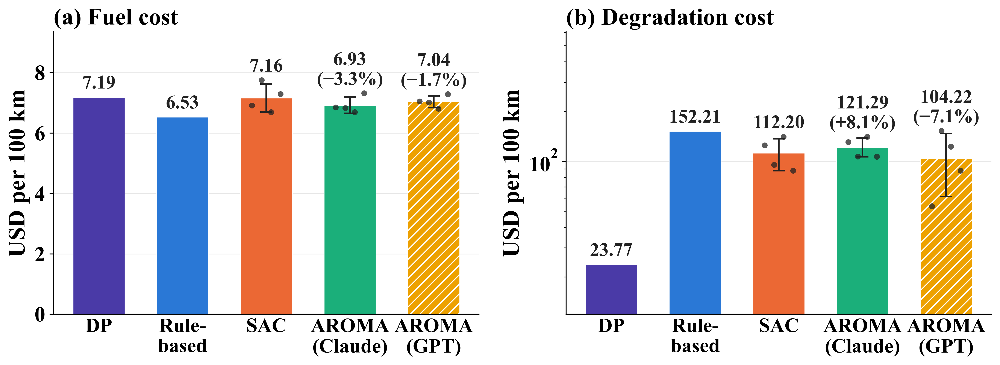

DP Rule-based             SAC  AROMA (Claude)     AROMA (GPT)
Fuel cost                  USD per 100 km   7.19       6.53     7.16 ± 0.46     6.93 ± 0.27     7.04 ± 0.20
                           vs SAC (%)       +0.3       -8.8            +0.0            -3.3            -1.7
FC degradation cost        USD per 100 km  19.19     144.66  105.30 ± 25.42  115.29 ± 17.06   97.92 ± 43.43
                           vs SAC (%)      -81.8      +37.4            +0.0            +9.5            -7.0
Battery degradation cost   USD per 100 km   4.58       7.55     6.90 ± 0.60     6.00 ± 0.15     6.30 ± 0.70
                           vs SAC (%)      -33.7       +9.4            +0.0           -13.0            -8.7
Degradation cost           USD per 100 km  23.77     152.21  112.20 ± 24.88  121.29 ± 17.11  104.22 ± 42.97
                           vs SAC (%)      -78.8      +35.7            +0.0            +8.1            -7.1
Total operating cost       USD per 100 km  30.95     158.75  119.37 ± 24.48  128.22 ± 16.93  111.26 ± 42.89
                           vs SAC (%)      -74.1      +33.0            +0.0            +7.4            -6.8
Degradation share of total %                76.8       95.9            94.0            94.6            93.7

In [14]:
COST_PARTS = [('h2_cost', 'Fuel cost', False),
              ('deg_cost', 'Degradation cost', True)]  # column, panel title, log axis


COST_RC = BOLD_RC  # bold, enlarged text (cell 3)


def cost_split_figure():
    with plt.rc_context(COST_RC):
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
        for ax, tag, (key, title, log) in zip(axes, 'ab', COST_PARTS):
            for j, m in enumerate(METHODS):
                st, mean = STYLE[m], ECON_MEAN.loc[m, key]
                ax.bar(j, mean, 0.62, color=st['color'], hatch=st['hatch'], edgecolor='white', linewidth=0.6, zorder=2)
                v = ECON[ECON.method == m][key].values
                top = mean
                if len(v) > 1:
                    sd = v.std(ddof=1)
                    ax.errorbar(j, mean, yerr=[[min(sd, mean - v.min()) if log else sd], [sd]], color=INK, linewidth=1.4,
                                capsize=5, capthick=1.4, zorder=4)
                    ax.scatter(j + np.linspace(-0.17, 0.17, len(v)), v, s=24, color=INK, alpha=0.75, linewidths=0, zorder=5)
                    top = max(v.max(), mean + sd)
                label = f'{mean:.2f}'
                if m in SEEDED[1:]:
                    label += f'\n({_pct((mean / ECON_MEAN.loc["SAC", key] - 1) * 100)})'
                ax.annotate(label, (j, top), xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontsize=16,
                            color=INK)
            if log:
                ax.set_yscale('log')
                ax.set_ylim(ECON_MEAN[key].min() * 0.5, ECON_MEAN[key].max() * 4)
            else:
                ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
            ax.set_xticks(range(len(METHODS)))
            # two lines so the larger names do not collide
            ax.set_xticklabels([m.replace(' (', '\n(').replace('Rule-based', 'Rule-\nbased') for m in METHODS], fontsize=17)
            ax.set_ylabel('USD per 100 km')
            ax.set_title(f'({tag}) {title}', loc='left')
            ax.grid(False, axis='x')
            ax.tick_params(axis='x', length=0)
        fig.tight_layout()
        save_fig('driving_cost_hydrogen_degradation', fig)
        plt.show()


def cost_table():
    # USD per 100 km: value at the seed-mean rates ± seed standard deviation, change against SAC, and the degradation share
    rows = {}
    for key, label in [('h2_cost', 'Fuel cost'), ('fc_cost', 'FC degradation cost'), ('bt_cost', 'Battery degradation cost'),
                       ('deg_cost', 'Degradation cost'), ('total_cost', 'Total operating cost')]:
        sd = ECON.groupby('method')[key].std(ddof=1).reindex(METHODS)
        rows[(label, 'USD per 100 km')] = [_fmt(ECON_MEAN.loc[m, key], sd[m], 1.0, 2) for m in METHODS]
        rows[(label, 'vs SAC (%)')] = [f'{(ECON_MEAN.loc[m, key] / ECON_MEAN.loc["SAC", key] - 1) * 100:+.1f}' for m in METHODS]
    rows[('Degradation share of total', '%')] = [f'{ECON_MEAN.loc[m, "deg_cost"] / ECON_MEAN.loc[m, "total_cost"] * 100:.1f}' for m in METHODS]
    t = pd.DataFrame(rows, index=METHODS).T
    if SAVE_FIGS:
        t.to_csv(FIG_OUTDIR / f'{FIG_PREFIX}__cost_hydrogen_degradation.csv')
        (FIG_OUTDIR / f'{FIG_PREFIX}__cost_hydrogen_degradation.tex').write_text(t.to_latex())
    return t


cost_split_figure()
cost_table()

## Figure 6 — cumulative cost over the vehicle life

Hydrogen bought so far plus one FC system and one battery pack at every end of life, at the seed-mean rates (the small steps
are battery packs, the large ones FC systems). The first FC system and pack are common to all methods and not counted.
End labels give the cumulative cost at `HORIZON_KM` and, for AROMA, the difference to SAC. That difference depends on
which replacements fall inside the horizon; Figure 4 is the horizon-free comparison.

[fig] multi_seed_v3cat__cumulative_cost -> paper_figures/


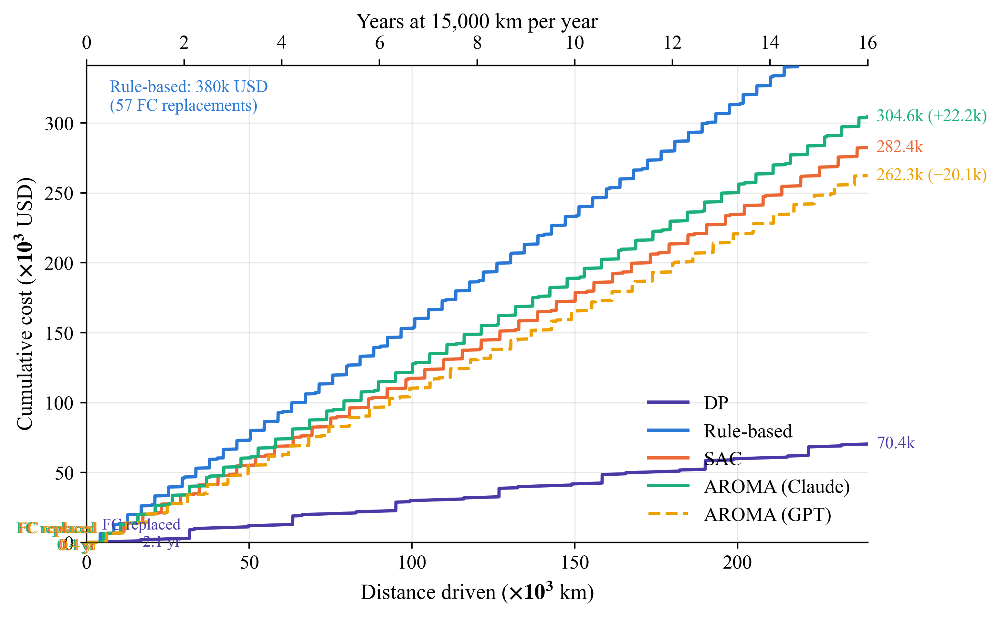

In [15]:
def cumulative_cost(method, d):
    # hydrogen bought so far plus one FC system and one battery pack for every end of life reached
    # (the first system and pack are common to all methods)
    r = ECON_MEAN.loc[method]
    return (r['eq'] / 1000.0 * H2_PRICE * d + FC_COST * np.floor(d / r.fc_life_km)
            + BATT_COST * np.floor(d / r.bt_life_km))


def cumulative_cost_figure():
    d = np.linspace(0.0, HORIZON_KM, 6001)
    fig, ax = plt.subplots(figsize=(7.8, 4.8))
    end = {m: cumulative_cost(m, HORIZON_KM) for m in METHODS}
    top = max(v for m, v in end.items() if m != 'Rule-based') * 1.12
    for m in METHODS:
        st = STYLE[m]
        ax.plot(d / 1e3, cumulative_cost(m, d) / 1e3, color=st['color'], linewidth=1.8, label=m,
                linestyle='--' if st['hatch'] else '-', zorder=3)
    for m in METHODS:  # first stack replacement inside the horizon
        life = ECON_MEAN.fc_life_km[m]
        if m != 'Rule-based' and life < HORIZON_KM:
            ax.annotate(f'FC replaced\n{life / ANNUAL_KM:.1f} yr', (life / 1e3, (cumulative_cost(m, life) - FC_COST / 2) / 1e3),
                        xytext=(-5, 0), textcoords='offset points', ha='right', va='center', fontsize=9, color=STYLE[m]['color'])
    order = sorted((m for m in METHODS if end[m] <= top), key=end.get)
    ys = np.array([end[m] for m in order]) / 1e3
    for i in range(1, len(ys)):  # keep the end labels apart
        ys[i] = max(ys[i], ys[i - 1] + top / 1e3 * 0.055)
    for m, y in zip(order, ys):
        text = f'{end[m] / 1e3:.1f}k'
        if m in SEEDED[1:]:
            text += f' ({(end[m] - end["SAC"]) / 1e3:+.1f}k)'.replace('-', '−')
        ax.annotate(text, (HORIZON_KM / 1e3, y), xytext=(5, 0), textcoords='offset points', ha='left', va='center',
                    fontsize=9.5, color=STYLE[m]['color'], annotation_clip=False)
    if end['Rule-based'] > top:
        n = int(np.floor(HORIZON_KM / ECON_MEAN.fc_life_km['Rule-based']))
        ax.annotate(f'Rule-based: {end["Rule-based"] / 1e3:.0f}k USD\n({n} FC replacements)', (0.03, 0.97),
                    xycoords='axes fraction', ha='left', va='top', fontsize=9.5, color=STYLE['Rule-based']['color'])
    ax.set_xlim(0, HORIZON_KM / 1e3)
    ax.set_ylim(0, top / 1e3)
    ax.set_xlabel('Distance driven ($\\times10^{3}$ km)')
    ax.set_ylabel('Cumulative cost ($\\times10^{3}$ USD)')
    years = ax.secondary_xaxis('top', functions=(lambda k: k * 1e3 / ANNUAL_KM, lambda y: y * ANNUAL_KM / 1e3))
    years.set_xlabel(f'Years at {ANNUAL_KM:,.0f} km per year')
    ax.legend(loc='lower right', frameon=False)
    save_fig('cumulative_cost', fig)
    plt.show()


cumulative_cost_figure()

## Table — per year of use

Seed-mean rates at `ANNUAL_KM` per year.

In [16]:
def annual_table():
    e, sac = ECON_MEAN, ECON_MEAN.loc['SAC']
    per_year = ANNUAL_KM / 100.0
    t = pd.DataFrame({
        'Eq. H2 (g/km)': e['eq'].map('{:.2f}'.format),
        'H2 (kg/yr)': (e['eq'] * ANNUAL_KM / 1000.0).map('{:.1f}'.format),
        'Hydrogen cost (USD/yr)': (e.h2_cost * per_year).map('{:,.0f}'.format),
        'FC life (1e3 km)': (e.fc_life_km / 1e3).map('{:,.0f}'.format),
        'FC life (h)': e.fc_life_h.map('{:,.0f}'.format),
        'FC life (yr)': e.fc_life_yr.map('{:,.1f}'.format),
        'Battery life (1e3 km)': (e.bt_life_km / 1e3).map('{:,.1f}'.format),
        'Battery life (yr)': e.bt_life_yr.map('{:,.2f}'.format),
        'FC degradation cost (USD/yr)': (e.fc_cost * per_year).map('{:,.0f}'.format),
        'Battery degradation cost (USD/yr)': (e.bt_cost * per_year).map('{:,.0f}'.format),
        'Total (USD/yr)': (e.total_cost * per_year).map('{:,.0f}'.format),
        'Total vs SAC (USD/yr)': ((e.total_cost - sac.total_cost) * per_year).map('{:+,.0f}'.format),
        'Total vs SAC (%)': ((e.total_cost / sac.total_cost - 1) * 100).map('{:+.1f}'.format),
    }).T
    if SAVE_FIGS:
        t.to_csv(FIG_OUTDIR / f'{FIG_PREFIX}__annual_economics.csv')
        (FIG_OUTDIR / f'{FIG_PREFIX}__annual_economics.tex').write_text(t.to_latex())
    return t


annual_table()

method,DP,Rule-based,SAC,AROMA (Claude),AROMA (GPT)
Eq. H2 (g/km),10.27,9.33,10.23,9.89,10.06
H2 (kg/yr),154.0,140.0,153.5,148.4,150.9
Hydrogen cost (USD/yr),"1,078",980,"1,075","1,039","1,056"
FC life (1e3 km),32,4,6,5,6
FC life (h),861,114,157,143,169
FC life (yr),2.1,0.3,0.4,0.4,0.4
Battery life (1e3 km),16.6,10.0,11.0,12.6,12.0
Battery life (yr),1.10,0.67,0.73,0.84,0.80
FC degradation cost (USD/yr),"2,878","21,699","15,795","17,294","14,688"
Battery degradation cost (USD/yr),687,"1,133","1,035",900,945


## Figure 7 — every AROMA iteration on the evaluation cycles

One column per seed, one line per backbone over iterations 1–6 (iteration 1 = the shared SAC baseline). Rows: total operating
cost (same economics as Figure 4, 4-cycle mean), equivalent H$_2$, and the number of evaluation cycles that end charge sustaining
(|ΔSOC| ≤ `CS_TOL`). The filled star is the champion the training-cycle gate adopted (`PICKS`); open markers are rejected
iterations. Dotted lines are DP and rule-based. A missing point is an iteration
without an actor (Claude seed 81 iteration 5: proposal failed). `ITER` holds the plotted values and `ITER_TABLE` the
training-cycle decision next to them.

[fig] multi_seed_v3cat__iterations_per_seed -> paper_figures/


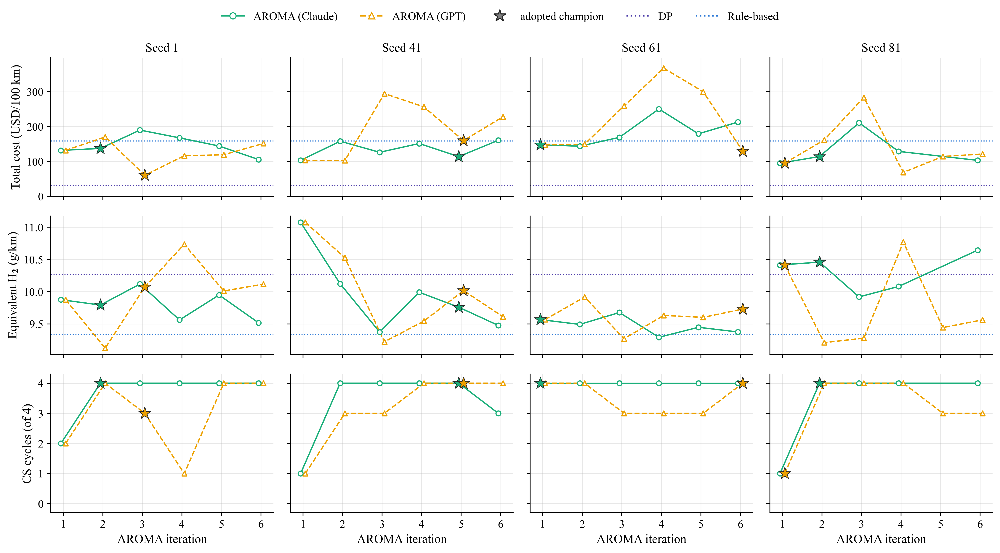

cs_ok          eq        total_cost        
agent          Claude  GPT Claude    GPT     Claude     GPT
seed iteration                                             
1    1            2.0  2.0   9.88   9.88     131.76  131.76
     2            4.0  4.0   9.79   9.12     137.37  170.21
     3            4.0  3.0  10.12  10.07     190.03   60.53
     4            4.0  1.0   9.56  10.74     167.68  116.14
     5            4.0  4.0   9.95  10.01     144.32  119.32
     6            4.0  4.0   9.52  10.12     105.52  151.54
41   1            1.0  1.0  11.08  11.08     103.07  103.07
     2            4.0  3.0  10.12  10.53     158.07  102.77
     3            4.0  3.0   9.37   9.22     126.27  294.74
     4            4.0  4.0   9.99   9.54     151.50  256.49
     5            4.0  4.0   9.76  10.02     113.90  159.71
     6            3.0  4.0   9.48   9.61     160.67  228.14
61   1            4.0  4.0   9.57   9.57     147.50  147.50
     2            4.0  4.0   9.49   9.92     143.87  149.38
     3            4.0  3.0   9.68   9.27     169.02  259.43
     4            4.0  3.0   9.29   9.63     250.48  367.80
     5            4.0  3.0   9.45   9.60     179.26  299.90
     6            4.0  4.0   9.38   9.73     212.98  129.65
81   1            1.0  1.0  10.41  10.41      95.13   95.13
     2            4.0  4.0  10.46   9.21     114.11  161.79
     3            4.0  4.0   9.92   9.28     210.79  283.57
     4            4.0  4.0  10.08  10.77     128.82   68.66
     5            NaN  3.0    NaN   9.44        NaN  114.30
     6            4.0  3.0  10.64   9.56     103.14  121.32

In [17]:
_it = RL.assign(dist=RL.cycle.map(DIST).astype(float), adsoc=(RL.final_soc - SOC0).abs())
_it['fc_km'], _it['bt_km'] = _it.fc_soh_loss / _it.dist, _it.battery_soh_loss / _it.dist
_it['eq'] = _it.equivalent_h2_g_per_km
_g = _it.groupby(['agent', 'seed', 'iteration', 'adoption_decision'])
ITER = economics(_g[['eq', 'fc_km', 'bt_km']].mean().reset_index())
ITER['cs_ok'] = _g.adsoc.apply(lambda v: int((v <= CS_TOL).sum())).values
ITER['n_cycles'] = _g.size().values
assert (ITER.n_cycles == len(CYCLES)).all()
ITER['picked'] = [PICKS[a][s] == i for a, s, i in zip(ITER.agent, ITER.seed, ITER.iteration)]
ITER_TABLE = ITER.pivot_table(index=['seed', 'iteration'], columns='agent',
                              values=['total_cost', 'eq', 'cs_ok'], aggfunc='first').round(2)

ITER_ROWS = [('total_cost', 'Total cost (USD/100 km)'), ('eq', 'Equivalent H$_2$ (g/km)'), ('cs_ok', f'CS cycles (of {len(CYCLES)})')]


def iteration_figure():
    fig, axes = plt.subplots(len(ITER_ROWS), len(SEEDS), figsize=(3.4 * len(SEEDS), 2.5 * len(ITER_ROWS)), sharex=True, sharey='row')
    off = {l: (k - (len(LLMS) - 1) / 2) * 0.12 for k, l in enumerate(LLMS)}  # keep the two backbones' markers apart
    for c, seed in enumerate(SEEDS):
        for r, (key, ylabel) in enumerate(ITER_ROWS):
            ax = axes[r, c]
            for llm in LLMS:
                st = STYLE[AROMA_LABEL[llm]]
                d = ITER[(ITER.agent == llm) & (ITER.seed == seed)].sort_values('iteration')
                x = d.iteration + off[llm]
                ax.plot(x, d[key], color=st['color'], linewidth=1.3, linestyle='--' if st['hatch'] else '-', zorder=2)
                ax.scatter(x, d[key], s=22, marker=st['marker'], facecolors='white', edgecolors=st['color'], linewidths=1.1, zorder=3)
                p = d[d.picked]
                ax.scatter(p.iteration + off[llm], p[key], s=150, marker='*', color=st['color'], edgecolors=INK, linewidths=0.6, zorder=4)
            if key != 'cs_ok':
                for m in ['DP', 'Rule-based']:
                    v = ECON_MEAN.loc[m, key] if key == 'total_cost' else summary.loc[m, key]
                    ax.axhline(v, color=STYLE[m]['color'], linewidth=1.0, linestyle=':', zorder=1)
            if r == 0:
                ax.set_title(f'Seed {seed}', fontsize=12)
            if c == 0:
                ax.set_ylabel(ylabel)
            if r == len(ITER_ROWS) - 1:
                ax.set_xlabel('AROMA iteration')
    top = ITER.total_cost.max() * 1.08
    axes[0, 0].set_ylim(0, top)
    axes[-1, 0].set_ylim(-0.3, len(CYCLES) + 0.3)
    axes[-1, 0].set_yticks(range(len(CYCLES) + 1))
    for ax in axes[-1]:
        ax.set_xticks(range(1, ITER.iteration.max() + 1))
    handles = [Line2D([], [], color=STYLE[AROMA_LABEL[l]]['color'], marker=STYLE[AROMA_LABEL[l]]['marker'], markerfacecolor='white',
                      linestyle='--' if STYLE[AROMA_LABEL[l]]['hatch'] else '-', label=AROMA_LABEL[l]) for l in LLMS]
    handles += [Line2D([], [], marker='*', color='0.5', markeredgecolor=INK, markersize=12, linestyle='none', label='adopted champion')]
    handles += [Line2D([], [], color=STYLE[m]['color'], linestyle=':', label=m) for m in ['DP', 'Rule-based']]
    fig.legend(handles=handles, ncol=len(handles), loc='upper center', bbox_to_anchor=(0.5, 1.0), frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    save_fig('iterations_per_seed', fig)
    plt.show()


iteration_figure()
if SAVE_FIGS:
    ITER_TABLE.to_csv(FIG_OUTDIR / f'{FIG_PREFIX}__iterations.csv')
ITER_TABLE

## Figure set B — AROMA picked as the cheapest iteration on the evaluation cycles

Same figures and tables as above, with the AROMA iteration per seed chosen **on the evaluation cycles themselves**: the
iteration among `ORACLE_ITERS` (the LLM-proposed rewards, iterations 2–6) with the lowest total operating cost (4-cycle mean,
Figure 7 / `ITER`). Set `ORACLE_REQUIRE_CS = True` to allow only iterations that are charge sustaining on all four cycles.

This is an **oracle selection**, not a deployable result: the cycles used to pick are the cycles reported, so the numbers are an
optimistic upper bound of what the candidate rewards contain. It answers "did the search produce a better reward than the one it
adopted?", while the adopted picks (Figures 1–7) answer "what does the training-cycle gate deliver?". SAC, DP and rule-based are
unchanged. Files are saved under the prefix `multi_seed_v3cat_heldout_best`; the cell restores the adopted-pick tables
(`M`, `PS`, `REL`, `ECON`, ...) at the end, so the cells above can be re-run in any order. `ORACLE` holds the oracle tables.

In [18]:
ORACLE_ITERS = range(2, 7)   # LLM-proposed rewards only (iteration 1 = the SAC baseline)
ORACLE_REQUIRE_CS = False    # True: only iterations charge sustaining on all evaluation cycles

_cand = ITER[ITER.iteration.isin(ORACLE_ITERS)]
if ORACLE_REQUIRE_CS:
    _cand = _cand[_cand.cs_ok == len(CYCLES)]
ORACLE_PICKS = {l: {int(s): int(g.loc[g.total_cost.idxmin(), 'iteration']) for s, g in _cand[_cand.agent == l].groupby('seed')}
                for l in LLMS}


def _pick_row(llm, seed, it):
    r = ITER[(ITER.agent == llm) & (ITER.seed == seed) & (ITER.iteration == it)].iloc[0]
    return it, r.total_cost, r['eq'], int(r.cs_ok)


_rows_pc = []
for llm in LLMS:
    for seed in SEEDS:
        a, o, b = _pick_row(llm, seed, PICKS[llm][seed]), _pick_row(llm, seed, ORACLE_PICKS[llm][seed]), _pick_row(llm, seed, 1)
        _rows_pc.append({'backbone': llm, 'seed': seed, 'SAC total': b[1],
                         'adopted it': a[0], 'adopted total': a[1], 'adopted eq': a[2], 'adopted CS': a[3],
                         'cheapest it': o[0], 'cheapest total': o[1], 'cheapest eq': o[2], 'cheapest CS': o[3],
                         'cheapest vs SAC (%)': (o[1] / b[1] - 1) * 100})
PICK_COMPARE = pd.DataFrame(_rows_pc).set_index(['backbone', 'seed'])
print('cheapest-on-evaluation picks:', ORACLE_PICKS)
if SAVE_FIGS:
    PICK_COMPARE.to_csv(FIG_OUTDIR / 'multi_seed_v3cat_heldout_best__pick_compare.csv')
PICK_COMPARE.round(2)

cheapest-on-evaluation picks: {'Claude': {1: 6, 41: 5, 61: 2, 81: 6}, 'GPT': {1: 3, 41: 2, 61: 6, 81: 4}}


SAC total  adopted it  adopted total  adopted eq  adopted CS  cheapest it  cheapest total  cheapest eq  cheapest CS  cheapest vs SAC (%)
backbone seed                                                                                                                                          
Claude   1        131.76           2         137.37        9.79           4            6          105.52         9.52            4               -19.92
         41       103.07           5         113.90        9.76           4            5          113.90         9.76            4                10.51
         61       147.50           1         147.50        9.57           4            2          143.87         9.49            4                -2.46
         81        95.13           2         114.11       10.46           4            6          103.14        10.64            4                 8.42
GPT      1        131.76           3          60.53       10.07           3            3           60.53        10.07            3               -54.06
         41       103.07           5         159.71       10.02           4            2          102.77        10.53            3                -0.29
         61       147.50           6         129.65        9.73           4            6          129.65         9.73            4               -12.10
         81        95.13           1          95.13       10.41           1            4           68.66        10.77            4               -27.83

method,DP,Rule-based,SAC,AROMA (Claude),AROMA (GPT)
eq,10.2663,9.3340,10.2339,9.8537,10.2750
raw,10.2663,9.3344,10.6288,9.9121,10.4693
adsoc,0.0000,0.0001,0.0560,0.0197,0.0305
fc,0.0000,0.0003,0.0002,0.0002,0.0002
bt,0.0002,0.0003,0.0003,0.0002,0.0002
cs_ok,4.0000,4.0000,2.0000,4.0000,3.5000
eq_vs_SAC_%,0.3165,-8.7933,0.0000,-3.7152,0.4016
raw_vs_SAC_%,-3.4101,-12.1778,0.0000,-6.7431,-1.5001
fc_vs_SAC_%,-82.3287,44.4140,0.0000,0.1247,-25.3299
bt_vs_SAC_%,-33.9718,8.1027,0.0000,-8.7073,-4.5468


[fig] multi_seed_v3cat_heldout_best__performance_by_cycle -> paper_figures/


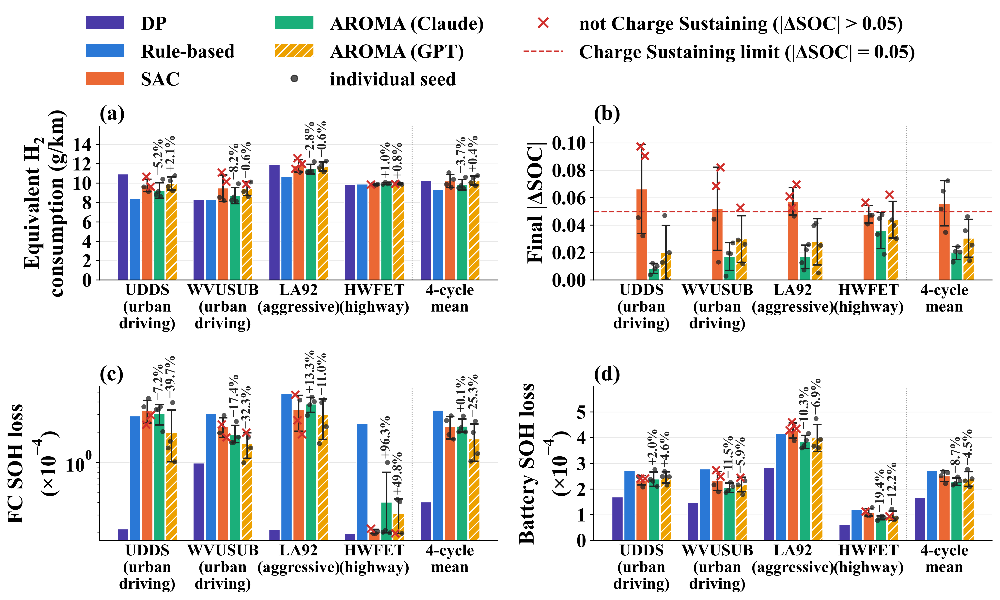

[fig] multi_seed_v3cat_heldout_best__cs_check_soc_correction -> paper_figures/


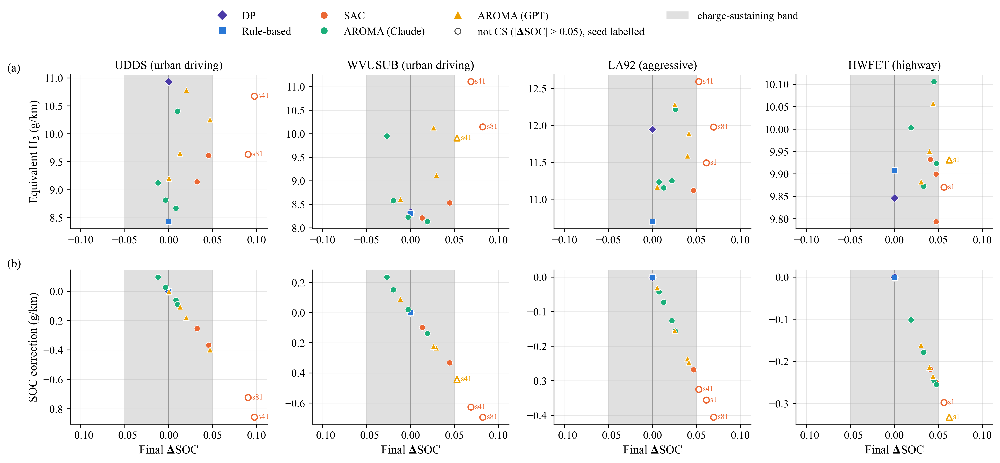

CS-matched (seed, cycle) pairs: ['s1 UDDS', 's1 WVUSUB', 's41 HWFET', 's61 UDDS', 's61 WVUSUB', 's61 LA92', 's61 HWFET', 's81 HWFET']
non-CS rollouts: ['SAC s1 LA92 dSOC +0.061', 'SAC s1 HWFET dSOC +0.056', 'SAC s41 UDDS dSOC +0.098', 'SAC s41 WVUSUB dSOC +0.069', 'SAC s41 LA92 dSOC +0.053', 'SAC s81 UDDS dSOC +0.090', 'SAC s81 WVUSUB dSOC +0.082', 'SAC s81 LA92 dSOC +0.070', 'AROMA (GPT) s1 HWFET dSOC +0.062', 'AROMA (GPT) s41 WVUSUB dSOC +0.053']


,eq all cycles,eq CS-matched,raw CS-matched,non-CS rollouts,n_cycles,eq all cycles vs SAC (%),eq CS-matched vs SAC (%)
SAC,10.234,9.531,9.785,8.0,8.0,0.000,0.000
AROMA (Claude),9.854,9.391,9.500,0.0,8.0,-3.715,-1.471
AROMA (GPT),10.275,9.704,9.816,2.0,8.0,0.402,1.822


[fig] multi_seed_v3cat_heldout_best__paired_seed_vs_sac -> paper_figures/


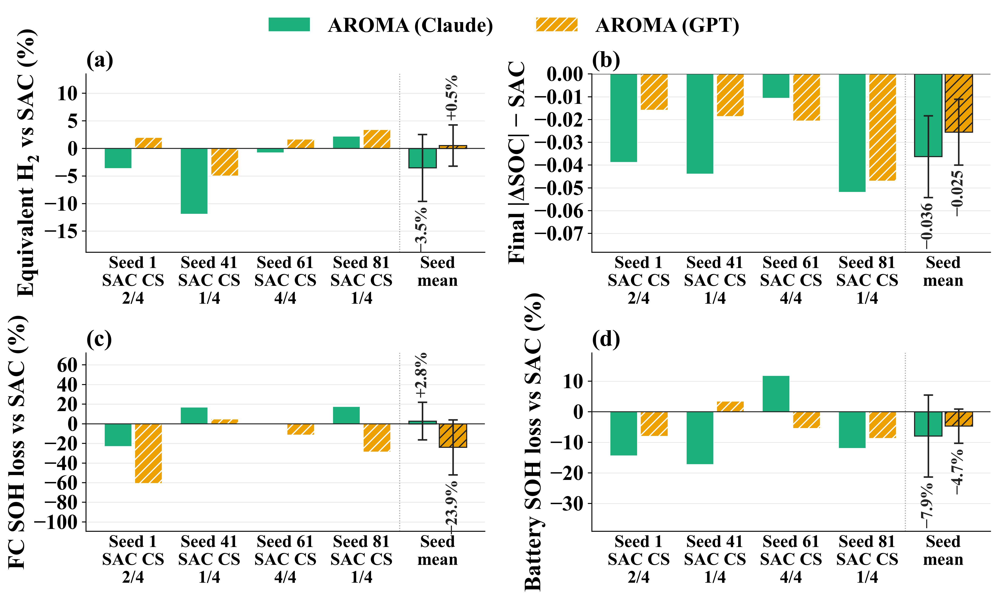

AROMA (Claude)                                AROMA (GPT)                             
                 eq     raw      fc      bt  adsoc          eq    raw      fc     bt  adsoc
seed                                                                                       
1            -3.636  -6.332 -22.957 -14.384 -0.039       1.983  0.831 -60.600 -7.987 -0.016
41          -11.890 -15.657  17.063 -17.232 -0.044      -4.961 -6.261   4.907  3.471 -0.019
61           -0.784  -1.501  -0.455  11.922 -0.011       1.706 -0.150 -11.408 -5.421 -0.021
81            2.211  -2.373  17.576 -11.928 -0.052       3.407  0.158 -28.684 -8.685 -0.047

,Claude,GPT,GPT − Claude,change (%),GPT lower (seeds)
metric,,,,,
Eq. H2 (g/km),9.854,10.275,0.421 ± 0.294,+4.3,0/4
|dSOC|,0.020,0.031,0.011 ± 0.017,+54.6,1/4
FC SOH loss (1e-4),2.290,1.708,-0.582 ± 0.365,-25.4,4/4
Batt. SOH loss (1e-4),2.293,2.398,0.105 ± 0.385,+4.6,1/4


[fig] multi_seed_v3cat_heldout_best__driving_cost_per_100km -> paper_figures/


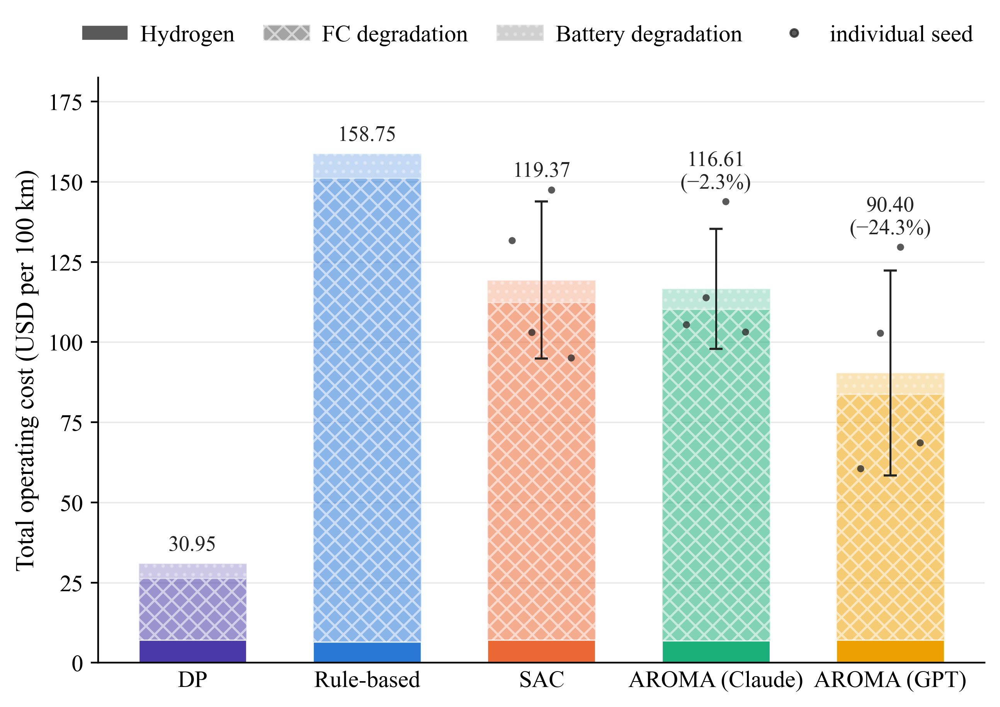

[fig] multi_seed_v3cat_heldout_best__driving_cost_hydrogen_degradation -> paper_figures/


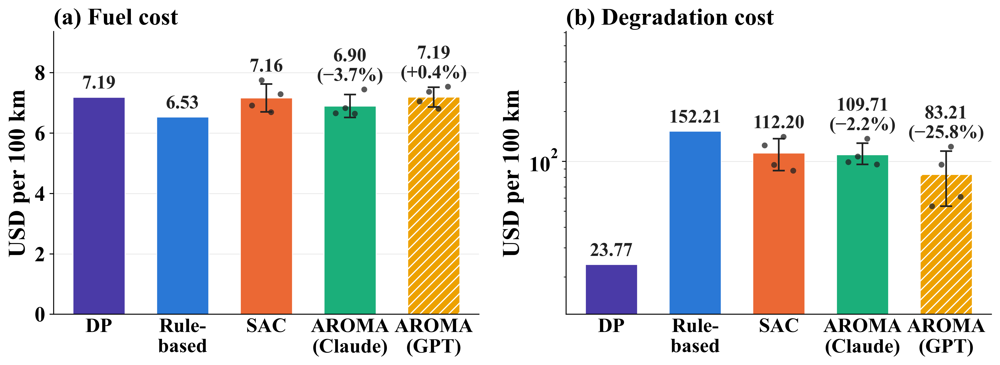

DP Rule-based             SAC  AROMA (Claude)    AROMA (GPT)
Fuel cost                  USD per 100 km   7.19       6.53     7.16 ± 0.46     6.90 ± 0.38    7.19 ± 0.32
                           vs SAC (%)       +0.3       -8.8            +0.0            -3.7           +0.4
FC degradation cost        USD per 100 km  19.19     144.66  105.30 ± 25.42  103.37 ± 18.62  76.58 ± 32.29
                           vs SAC (%)      -81.8      +37.4            +0.0            -1.8          -27.3
Battery degradation cost   USD per 100 km   4.58       7.55     6.90 ± 0.60     6.34 ± 0.40    6.63 ± 0.77
                           vs SAC (%)      -33.7       +9.4            +0.0            -8.1           -4.0
Degradation cost           USD per 100 km  23.77     152.21  112.20 ± 24.88  109.71 ± 18.96  83.21 ± 32.10
                           vs SAC (%)      -78.8      +35.7            +0.0            -2.2          -25.8
Total operating cost       USD per 100 km  30.95     158.75  119.37 ± 24.48  116.61 ± 18.75  90.40 ± 31.93
                           vs SAC (%)      -74.1      +33.0            +0.0            -2.3          -24.3
Degradation share of total %                76.8       95.9            94.0            94.1           92.0

[fig] multi_seed_v3cat_heldout_best__cumulative_cost -> paper_figures/


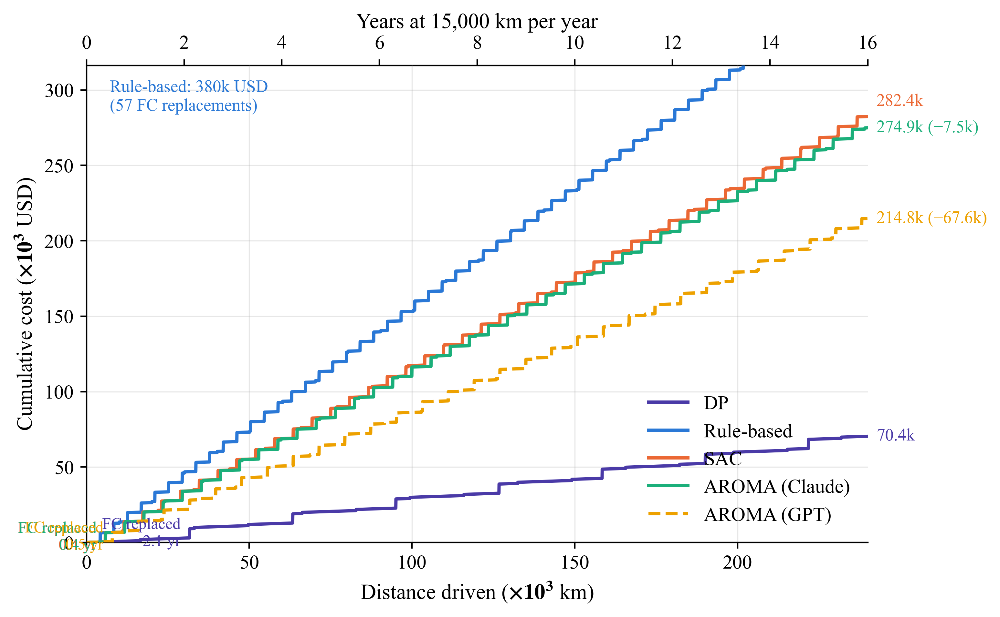

method,DP,Rule-based,SAC,AROMA (Claude),AROMA (GPT)
Eq. H2 (g/km),10.27,9.33,10.23,9.85,10.28
H2 (kg/yr),154.0,140.0,153.5,147.8,154.1
Hydrogen cost (USD/yr),"1,078",980,"1,075","1,035","1,079"
FC life (1e3 km),32,4,6,6,8
FC life (h),861,114,157,160,216
FC life (yr),2.1,0.3,0.4,0.4,0.5
Battery life (1e3 km),16.6,10.0,11.0,12.0,11.4
Battery life (yr),1.10,0.67,0.73,0.80,0.76
FC degradation cost (USD/yr),"2,878","21,699","15,795","15,505","11,488"
Battery degradation cost (USD/yr),687,"1,133","1,035",951,994


In [19]:
_ADOPTED = dict(M=M, PS=PS, summary=summary, REL=REL, RATE=RATE, ECON=ECON, ECON_MEAN=ECON_MEAN, FIG_PREFIX=FIG_PREFIX)
try:
    M = build_methods(ORACLE_PICKS)
    PS = per_seed(M)
    summary = summarize(PS)
    REL = rel_table()
    RATE, ECON, ECON_MEAN = econ_tables(M)
    FIG_PREFIX = 'multi_seed_v3cat_heldout_best'
    display(summary.T.round(4))
    performance_figure()                 # Figure 1
    cs_check_figure()                    # Figure 1b
    display(cs_matched_table().round(3))
    paired_seed_figure()                 # Figure 2
    display(REL.round(3))
    for i, a in enumerate(LLMS):
        for b in LLMS[i + 1:]:
            display(head_to_head(a, b))
    cost_figure()                        # Figure 4
    cost_split_figure()                  # Figure 4b
    display(cost_table())
    cumulative_cost_figure()             # Figure 6
    display(annual_table())
    ORACLE = dict(picks=ORACLE_PICKS, M=M, PS=PS, summary=summary, REL=REL, ECON=ECON, ECON_MEAN=ECON_MEAN)
finally:
    globals().update(_ADOPTED)  # back to the adopted picks